# Lens 1–9 Como — match analysis (working notebook)

UEFA Champions League 2026/27, league phase, 4 November 2026, Stade Bollaert-Delelis.

Como's nine goals equal the record for the **most goals scored by one team in a Champions League match** (Bayern Munich 9–2 Dinamo Zagreb, 2024), and the eight-goal margin equals the competition's **biggest win** (Liverpool 8–0 Beşiktaş, 2007; Real Madrid 8–0 Malmö, 2015). It is the first time any side has won by that margin away from home.

This notebook downloads the event data from WhoScored with [`soccerdata`](https://github.com/probberechts/soccerdata) and builds each chart step by step with [`mplsoccer`](https://mplsoccer.readthedocs.io/), finishing with Tasos Douvikas's man-of-the-match performance. The finished charts, as reusable functions on one report, are in **`Match_Report.ipynb`**.

**Pitch coordinates:** Opta style, 0–100 on both axes, each team attacking left → right. Lens's events are flipped (`100 - x`, `100 - y`) when both teams share a pitch.

## 1. Setup and data

The scraping cells (WhoScored opens a browser window) only need running once — the events are saved to `Lens_Como.csv`, so you can start from *Load the saved events*.

In [1]:
%pip install soccerdata mplsoccer

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch, VerticalPitch
import soccerdata as sd
import ast
import numpy as np
from matplotlib.patches import Rectangle

COMO, LENS = "Como", "Lens"

[11/10/26 16:54:55] INFO     No custom team name replacements found. You can configure these in       ]8;id=990262;file:///usr/local/lib/python3.13/site-packages/soccerdata/_config.py\_config.py]8;;\:]8;id=990263;file:///usr/local/lib/python3.13/site-packages/soccerdata/_config.py#91\91]8;;\
                             /root/soccerdata/config/teamname_replacements.json.                                   

                    INFO     No custom league dict found. You can configure additional leagues in    ]8;id=990269;file:///usr/local/lib/python3.13/site-packages/soccerdata/_config.py\_config.py]8;;\:]8;id=990270;file:///usr/local/lib/python3.13/site-packages/soccerdata/_config.py#189\189]8;;\
                             /root/soccerdata/config/league_dict.json.                                             

In [3]:
sd.WhoScored.available_leagues()

['ENG-Premier League',
 'ESP-La Liga',
 'FRA-Ligue 1',
 'GER-Bundesliga',
 'INT-Champions League',
 'INT-European Championship',
 "INT-Women's World Cup",
 'INT-World Cup',
 'ITA-Serie A']

In [4]:
ws = sd.WhoScored(leagues="INT-Champions League", seasons="2627", headless=False)

                    INFO     Saving cached data to C:\Users\samj7\soccerdata\data\WhoScored          _common.py:300

In [5]:
schedule = ws.read_schedule().reset_index()

[11/10/26 12:31:11] INFO     Retrieving calendar for INT-Champions League 2627                     whoscored.py:368

[11/10/26 12:31:25] INFO     [1/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:31:35] INFO     [2/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:31:41] INFO     [3/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:31:47] INFO     [4/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:31:57] INFO     [5/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

In [6]:
schedule["home_team"].unique()

<StringArray>
[         'AEK Athens',   'Borussia Dortmund',         'Club Brugge',
            'FC Porto',               'Lille',         'Real Madrid',
           'Barcelona',           'Liverpool',              'Napoli',
 'Paris Saint-Germain',         'Sporting CP',       'VfB Stuttgart',
       'Bayern Munich',                'Como',          'Fenerbahce',
   'Manchester United',       'PSV Eindhoven',       'Slavia Prague',
             'Arsenal',     'Atletico Madrid',         'Galatasaray',
               'Inter',                'Lens',          'RB Leipzig',
            'Sabah FK',              'Viking',          'Villarreal',
         'Aston Villa',         'Bodoe/Glimt',           'Feyenoord',
                'LASK',     'Manchester City',          'Real Betis',
                'Roma',    'Shakhtar Donetsk',   'Slovan Bratislava']
Length: 36, dtype: str

In [7]:
game = schedule[
    (schedule["home_team"] == "Lens") & (schedule["away_team"] == "Como")
]
game

,league,season,game,stage_id,game_id,status,start_time,home_team_id,home_team,home_yellow_cards,...,period,extra_result_field,home_extratime_score,away_extratime_score,home_penalty_score,away_penalty_score,started_at_utc,first_half_ended_at_utc,second_half_started_at_utc,stage
67,INT-Champions League,2627,2026-11-04 Lens-Como,25800,2029241,6,2026-11-04T20:00:00,309,Lens,2,...,7,None,None,None,None,None,2026-11-04T20:01:52Z,2026-11-04T20:50:59Z,2026-11-04T21:06:55Z,None


In [8]:
game_id = int(game["game_id"].iloc[0])

events = ws.read_events(match_id=game_id).reset_index()
events.to_csv("Lens_Como.csv", index=False)
events.shape

[11/10/26 12:32:17] INFO     Retrieving calendar for INT-Champions League 2627                     whoscored.py:368

[11/10/26 12:32:28] INFO     [1/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:32:37] INFO     [2/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:32:46] INFO     [3/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:32:52] INFO     [4/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:33:01] INFO     [5/5] Retrieving fixtures for INT-Champions League 2627               whoscored.py:399

[11/10/26 12:33:09] INFO     [1/1] Retrieving game with id=2029241                                 whoscored.py:691

(1736, 30)

### Load the saved events

In [9]:
events = pd.read_csv("Lens_Como.csv")

# guessed receiver of each pass = the player in the next event
events["next_player"] = events["player"].shift(-1)
events["next_team"] = events["team"].shift(-1)

events.shape

(1736, 32)

In [10]:
print(events["type"].value_counts().to_string())

type
Pass               1192
BallRecovery         84
TakeOn               57
BallTouch            56
Foul                 46
Clearance            44
Tackle               37
Interception         26
Aerial               26
Challenge            23
CornerAwarded        20
BlockedPass          16
Dispossessed         14
MissedShots          11
Goal                 10
SubstitutionOff       9
SubstitutionOn        9
SavedShot             8
Save                  8
KeeperPickup          7
Error                 6
End                   6
Start                 4
GoodSkill             4
FormationChange       3
Card                  2
KeeperSweeper         2
FormationSet          2
Smother               1
OffsideGiven          1
OffsidePass           1
OffsideProvoked       1

## 2. Shot map

Como attack left → right; Lens's shots are flipped so they attack right → left.

In [11]:
C_Shots = events[(events["is_shot"] == True) & (events["team"] == "Como")]
C_Goals = C_Shots[C_Shots["is_goal"] == True]
L_Shots = events[(events["is_shot"] == True) & (events["team"] == "Lens")]
L_Goals = L_Shots[L_Shots["is_goal"] == True]

L_Shots_flipped = L_Shots.copy()
L_Shots_flipped["x"] = 100 - L_Shots_flipped["x"]
L_Shots_flipped["y"] = 100 - L_Shots_flipped["y"]

L_Goals_flipped = L_Goals.copy()
L_Goals_flipped["x"] = 100 - L_Goals_flipped["x"]
L_Goals_flipped["y"] = 100 - L_Goals_flipped["y"]

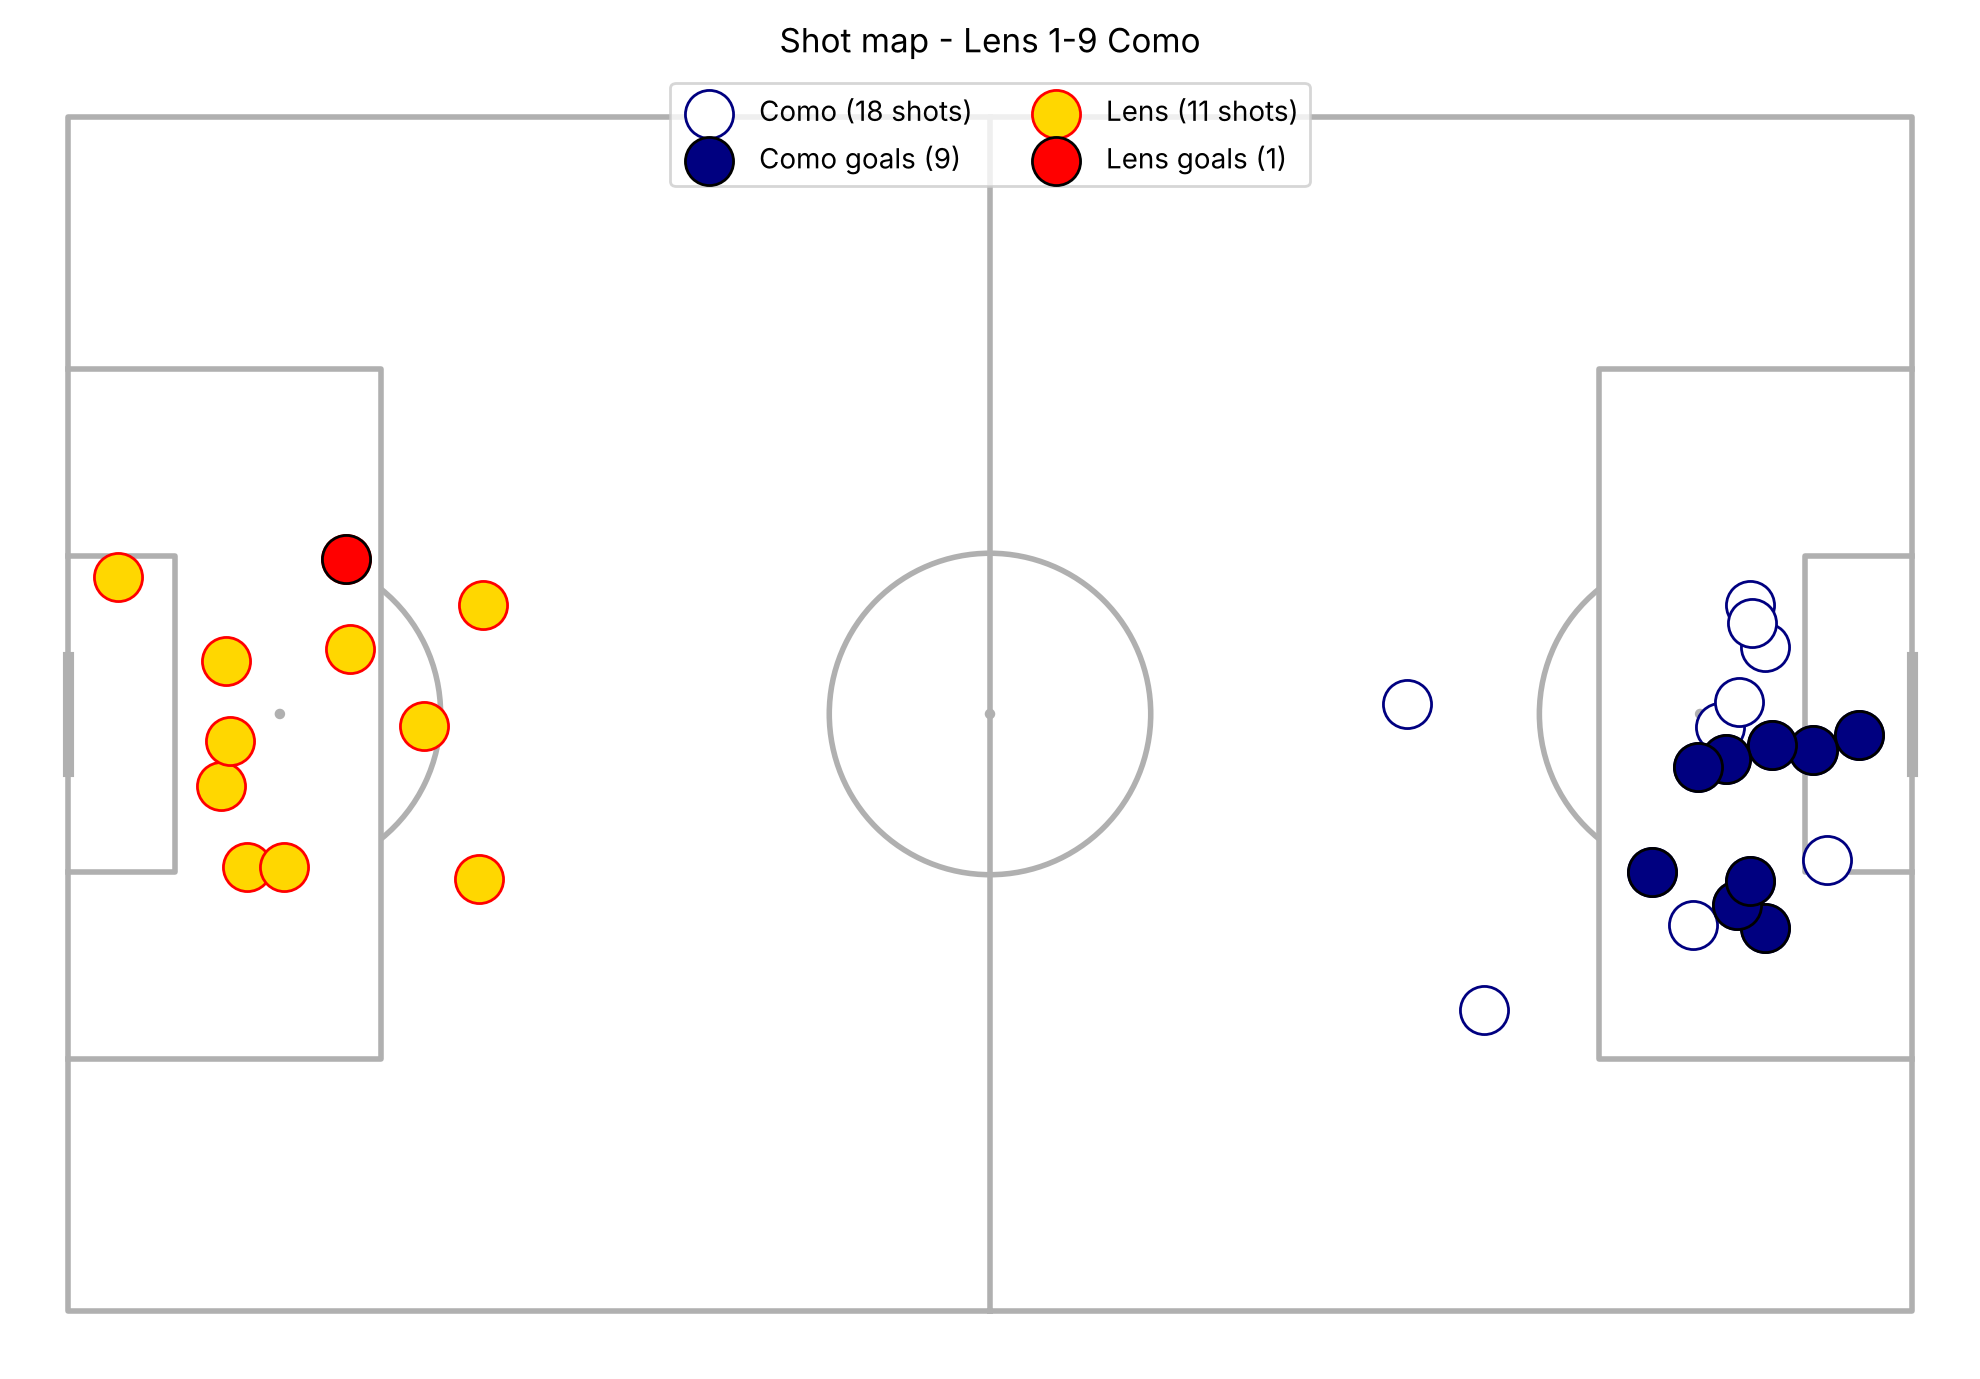

In [12]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.scatter(C_Shots["x"], C_Shots["y"], color="white", s=300, ax=ax, edgecolor="navy", label=f"Como ({len(C_Shots)} shots)")
pitch.scatter(C_Goals["x"], C_Goals["y"], color="navy", s=300, ax=ax, edgecolor="black", label=f"Como goals ({len(C_Goals)})")
pitch.scatter(L_Shots_flipped["x"], L_Shots_flipped["y"], color="gold", s=300, ax=ax, edgecolor="red", label=f"Lens ({len(L_Shots)} shots)")
pitch.scatter(L_Goals_flipped["x"], L_Goals_flipped["y"], color="red", s=300, ax=ax, edgecolor="black", label=f"Lens goals ({len(L_Goals)})")

ax.set_title("Shot map - Lens 1-9 Como")
ax.legend(loc="upper center", ncol=2)
plt.show()

## 3. Como: average positions and passing network

Completed passes before Como's first substitution, so only the starting XI is shown.

In [13]:
c_passes = events[(events["type"] == "Pass") & (events["team"] == "Como")]
c_completed = c_passes[c_passes["outcome_type"] == "Successful"]

c_first_sub = events[(events["type"] == "SubstitutionOn") & (events["team"] == "Como")]["minute"].min()

starters = c_completed[c_completed["minute"] < c_first_sub]

avg = starters.groupby("player").agg(
    x = ("x", "mean"),
    y = ("y", "mean"),
    n = ("x", "size")
).sort_values("n")

c_first_sub, avg

(np.int64(57),
                            x          y   n
 player                                     
 Tasos Douvikas     73.175000  62.225000   4
 Jean Butez          9.552941  50.458824  17
 Álex Valle         49.417391  77.930435  23
 Maxence Caqueret   48.850000  66.019231  26
 Nico Paz           55.269231  27.373077  26
 Lucas da Cunha     49.971429  34.022857  35
 Marc Oliver Kempf  31.102778  62.766667  36
 Jacobo Ramón       35.783333  30.469444  36
 Yan Couto          51.807895  15.510526  38
 Máximo Perrone     47.373171  43.939024  41
 Luis Milla         50.442222  48.182222  45)

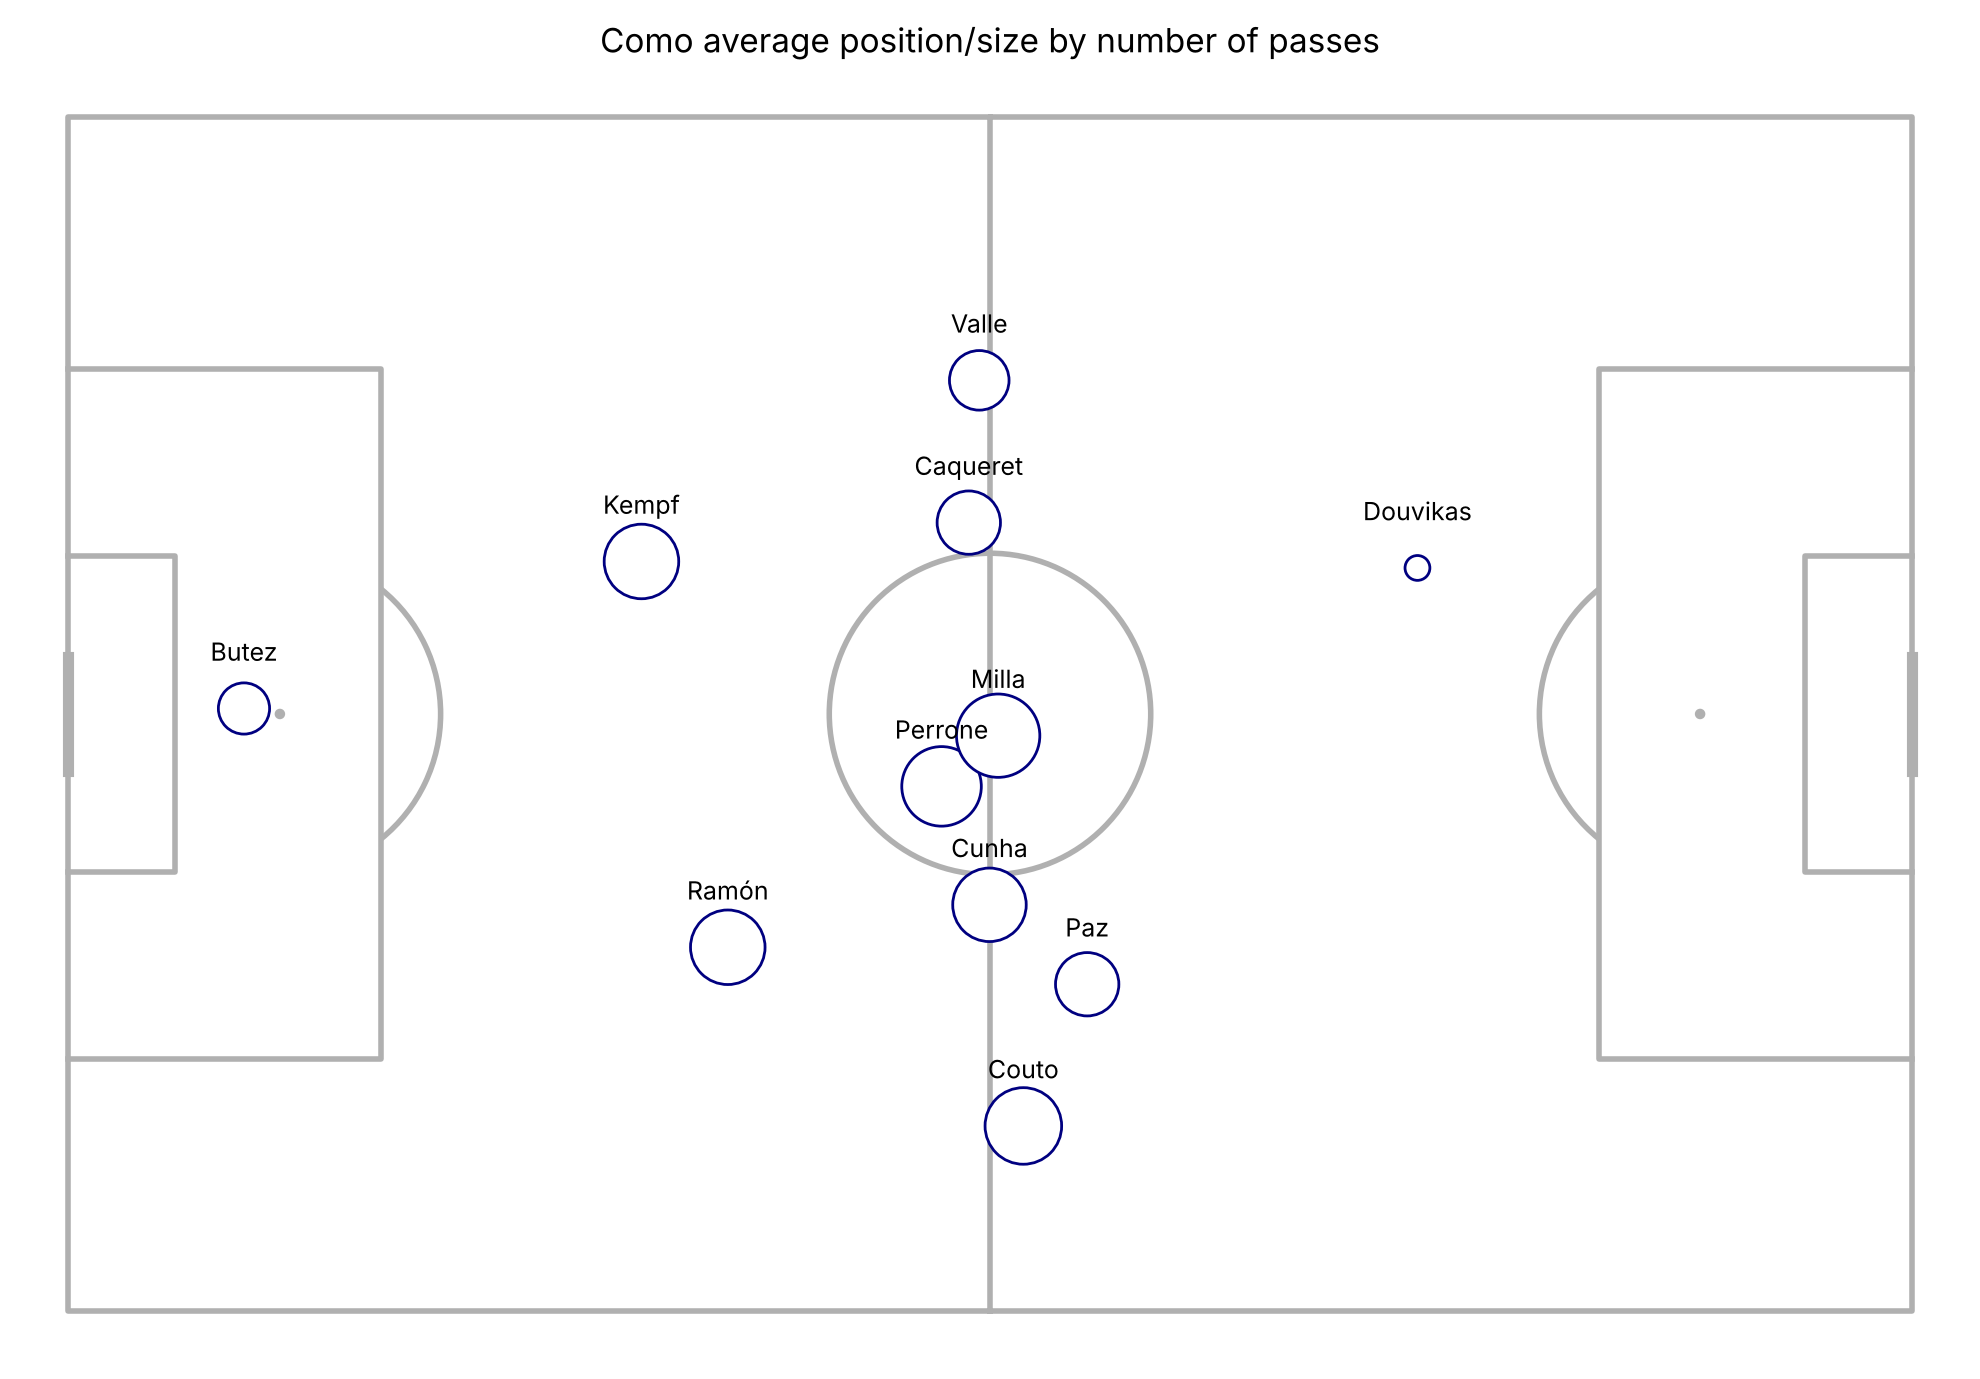

In [14]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.scatter(avg["x"], avg["y"], ax=ax, s=avg["n"] * 20, color="white", edgecolor="navy")
for player, pos in avg.iterrows():
    pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4), ax=ax, ha="center", fontsize=9)

ax.set_title("Como average position/size by number of passes")

plt.show()

In [15]:
link = starters[starters["next_team"] == "Como"]
pairs = link.groupby(["player", "next_player"]).size().reset_index(name="count")
pairs = pairs[pairs["count"] >= 3]

pairs["x_start"] = pairs["player"].map(avg["x"])
pairs["y_start"] = pairs["player"].map(avg["y"])
pairs["x_end"] = pairs["next_player"].map(avg["x"])
pairs["y_end"] = pairs["next_player"].map(avg["y"])
pairs["x_arrow"] = pairs["x_start"] + 0.6 * (pairs["x_end"] - pairs["x_start"])
pairs["y_arrow"] = pairs["y_start"] + 0.6 * (pairs["y_end"] - pairs["y_start"])

pairs.sort_values("count", ascending=False).head()

,player,next_player,count,x_start,y_start,x_end,y_end,x_arrow,y_arrow
31,Luis Milla,Nico Paz,11,50.442222,48.182222,55.269231,27.373077,53.338427,35.696735
30,Luis Milla,Máximo Perrone,10,50.442222,48.182222,47.373171,43.939024,48.600791,45.636304
34,Marc Oliver Kempf,Jacobo Ramón,9,31.102778,62.766667,35.783333,30.469444,33.911111,43.388333
76,Yan Couto,Máximo Perrone,9,51.807895,15.510526,47.373171,43.939024,49.147060,32.567625
82,Álex Valle,Maxence Caqueret,9,49.417391,77.930435,48.850000,66.019231,49.076957,70.783712


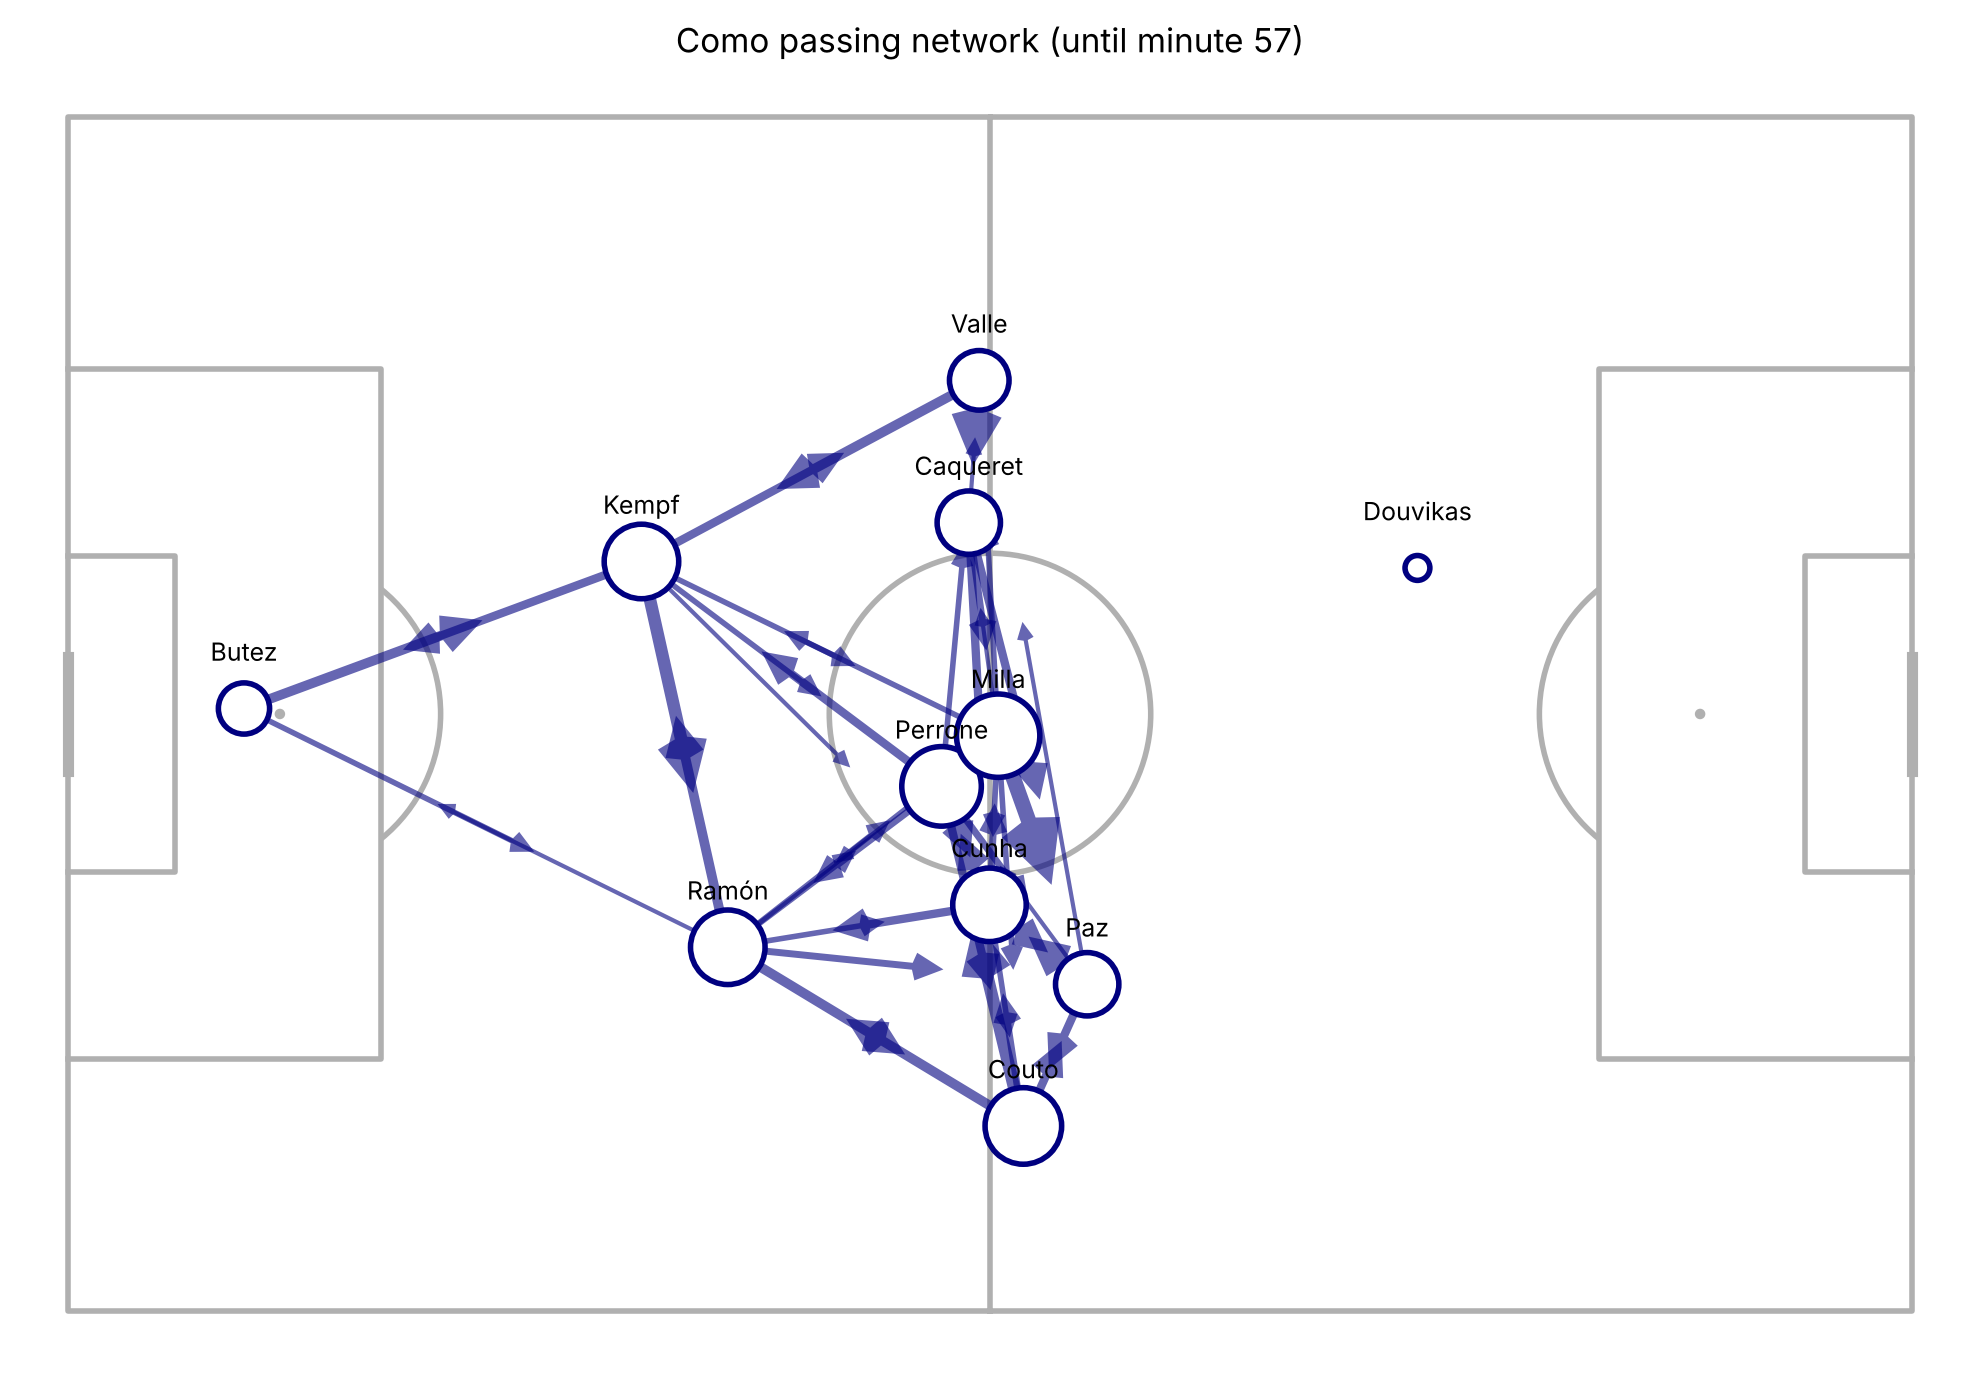

In [16]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

for _, row in pairs.iterrows():
    pitch.arrows(row["x_start"], row["y_start"], row["x_arrow"], row["y_arrow"],
                 width=row["count"] * 0.5, headwidth=4, headlength=4,
                 color="navy", alpha=0.6, ax=ax, zorder=1)

pitch.scatter(avg["x"], avg["y"], ax=ax, s=avg["n"] * 20, color="white", edgecolor="navy", linewidth=2, zorder=2)

for player, pos in avg.iterrows():
    pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4), ax=ax, ha="center", fontsize=9)

ax.set_title(f"Como passing network (until minute {c_first_sub})")
plt.show()

## 4. Lens: average positions and passing network

Same method for Lens. Lens made a double substitution at half-time, so this covers the first half only.

In [17]:
l_passes = events[(events["type"] == "Pass") & (events["team"] == "Lens")]
l_completed = l_passes[l_passes["outcome_type"] == "Successful"]

l_first_sub = events[(events["type"] == "SubstitutionOn") & (events["team"] == "Lens")]["minute"].min()
l_starters = l_completed[l_completed["minute"] < l_first_sub]

l_avg = l_starters.groupby("player").agg(
    x = ("x", "mean"),
    y = ("y", "mean"),
    n = ("x", "size")
).sort_values("n")

l_link = l_starters[l_starters["next_team"] == "Lens"]
l_pairs = l_link.groupby(["player", "next_player"]).size().reset_index(name="count")
l_pairs = l_pairs[l_pairs["count"] >= 3]

l_pairs["x_start"] = l_pairs["player"].map(l_avg["x"])
l_pairs["y_start"] = l_pairs["player"].map(l_avg["y"])
l_pairs["x_end"] = l_pairs["next_player"].map(l_avg["x"])
l_pairs["y_end"] = l_pairs["next_player"].map(l_avg["y"])
l_pairs["x_arrow"] = l_pairs["x_start"] + 0.6 * (l_pairs["x_end"] - l_pairs["x_start"])
l_pairs["y_arrow"] = l_pairs["y_start"] + 0.6 * (l_pairs["y_end"] - l_pairs["y_start"])

l_first_sub, l_avg

(np.int64(45),
                           x          y   n
 player                                    
 Franjo Ivanovic   42.900000  48.833333   6
 Thorgan Hazard    68.083333  51.250000   6
 Michal Skóras     57.840000   9.160000  10
 Robin Risser      15.364286  50.628571  14
 Amadou Haidara    32.300000  59.618750  16
 Matthieu Udol     34.335294  89.423529  17
 Florian Thauvin   57.015000  26.195000  20
 Michaël Cuisance  53.680952  32.090476  21
 Kyllian Antonio   34.670370  78.055556  27
 Samson Baidoo     39.975000  39.403571  28
 Ruben Aguilar     51.821053  15.718421  38)

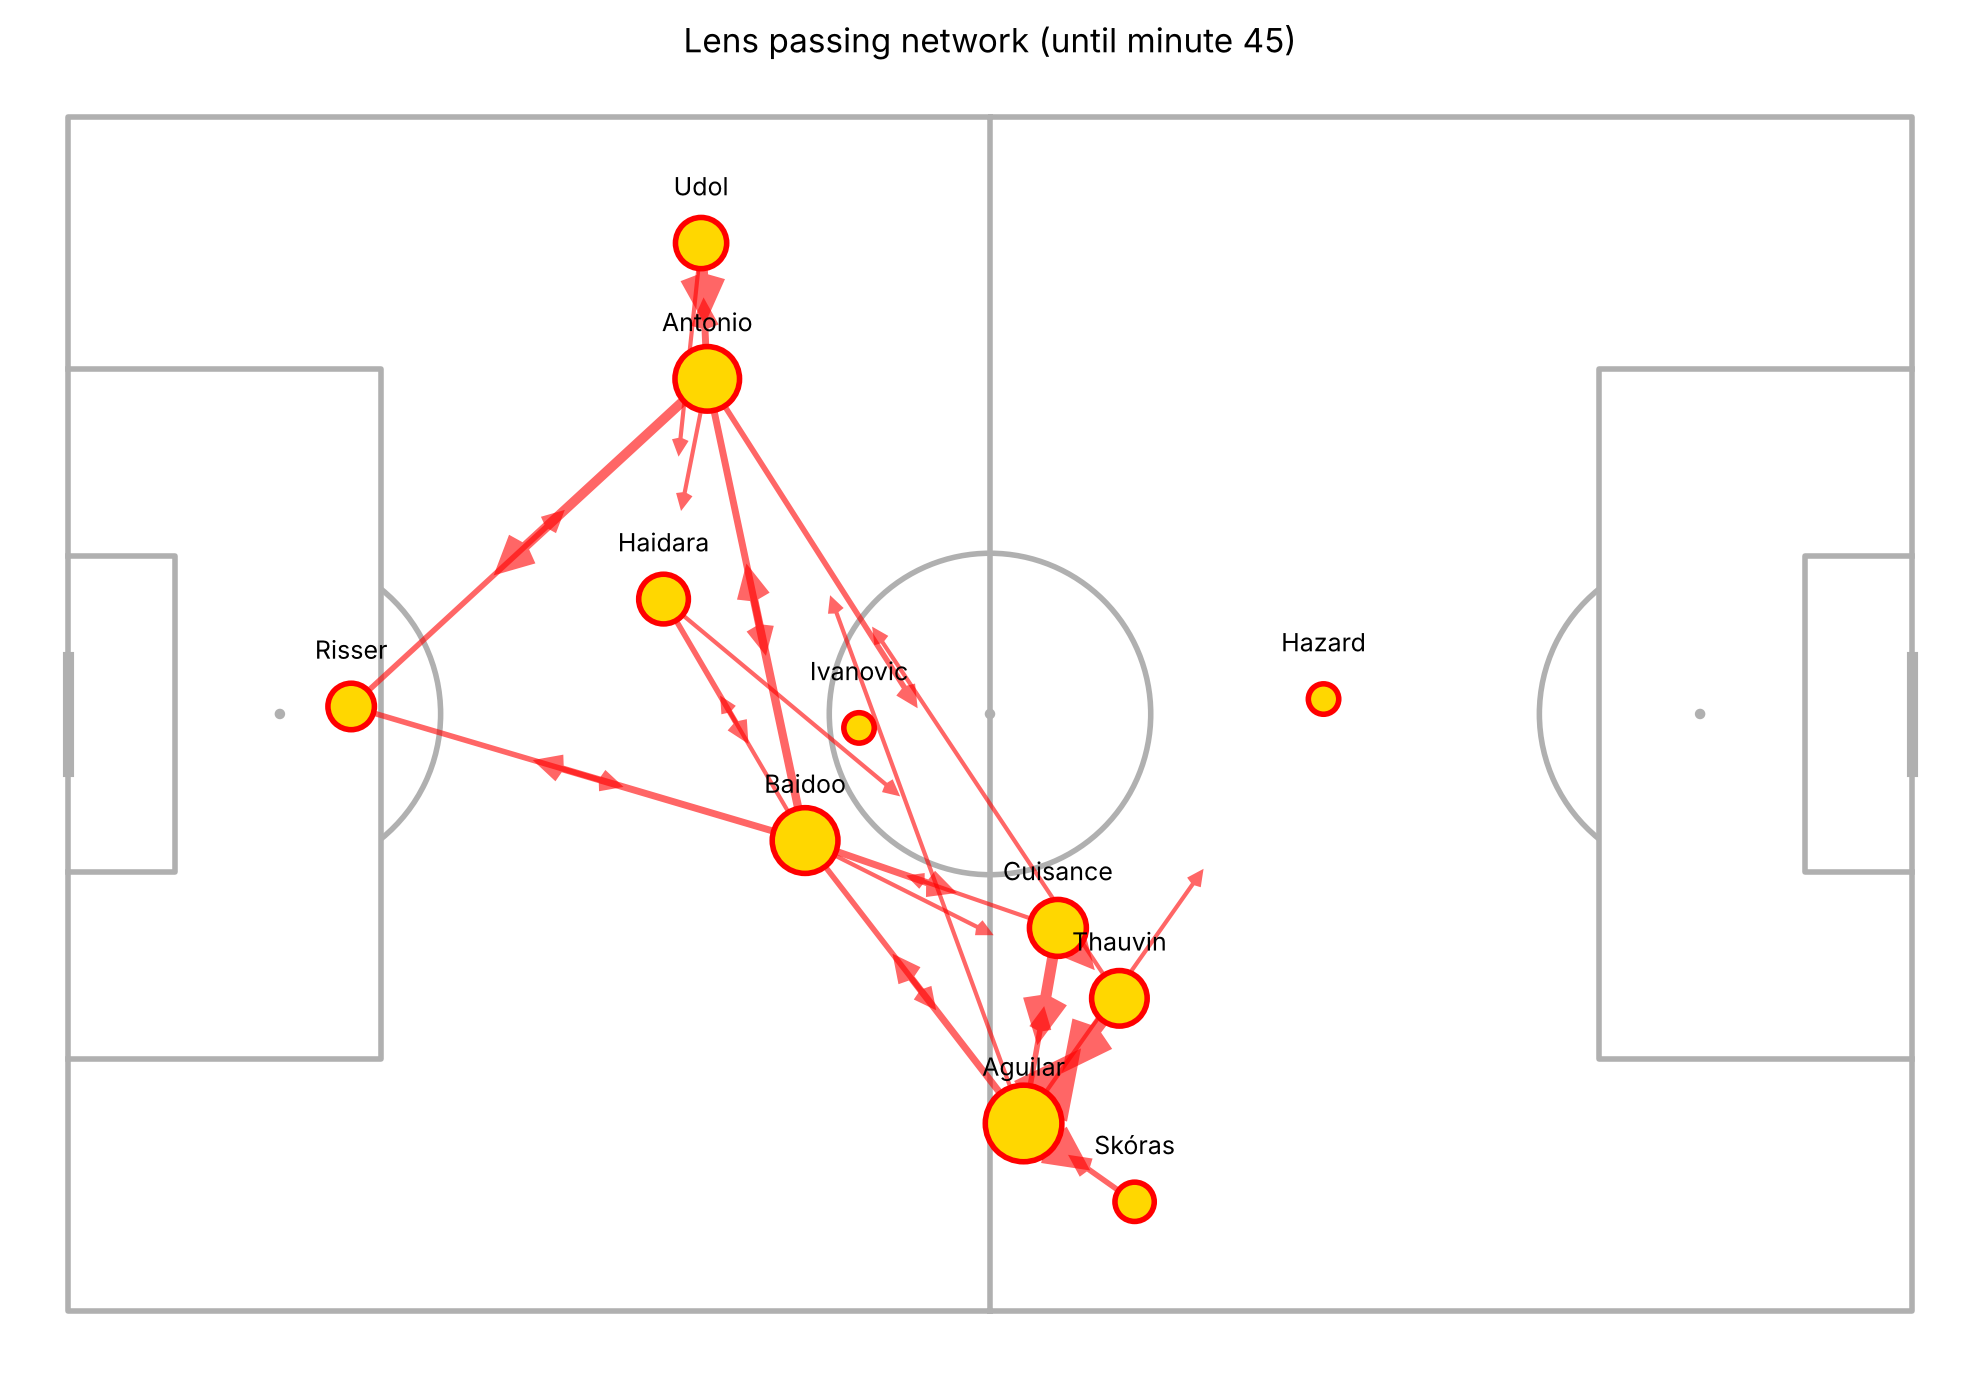

In [18]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

for _, row in l_pairs.iterrows():
    pitch.arrows(row["x_start"], row["y_start"], row["x_arrow"], row["y_arrow"],
                 width=row["count"] * 0.5, headwidth=4, headlength=4,
                 color="red", alpha=0.6, ax=ax, zorder=1)

pitch.scatter(l_avg["x"], l_avg["y"], ax=ax, s=l_avg["n"] * 20, color="gold", edgecolor="red", linewidth=2, zorder=2)

for player, pos in l_avg.iterrows():
    pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4), ax=ax, ha="center", fontsize=9)

ax.set_title(f"Lens passing network (until minute {l_first_sub})")
plt.show()

## 5. Como: where passes ended and chance creation

Key passes are passes that led directly to a shot.

In [19]:
ends = c_completed["end_x"]

defensive = (ends < 33.3).sum()
middle = ((ends >= 33.3) & (ends < 66.7)).sum()
final = (ends >= 66.7).sum()

key_passes = c_passes[c_passes["qualifiers"].str.contains("KeyPass", na=False)]

c_stats = pitch.bin_statistic(c_completed["end_x"], c_completed["end_y"], statistic="count", bins=(6, 5), normalize=True)
kp_stats = pitch.bin_statistic(key_passes["x"], key_passes["y"], statistic="count", bins=(6, 5))

[defensive, middle, final, len(key_passes)]

[np.int64(184), np.int64(331), np.int64(96), 14]

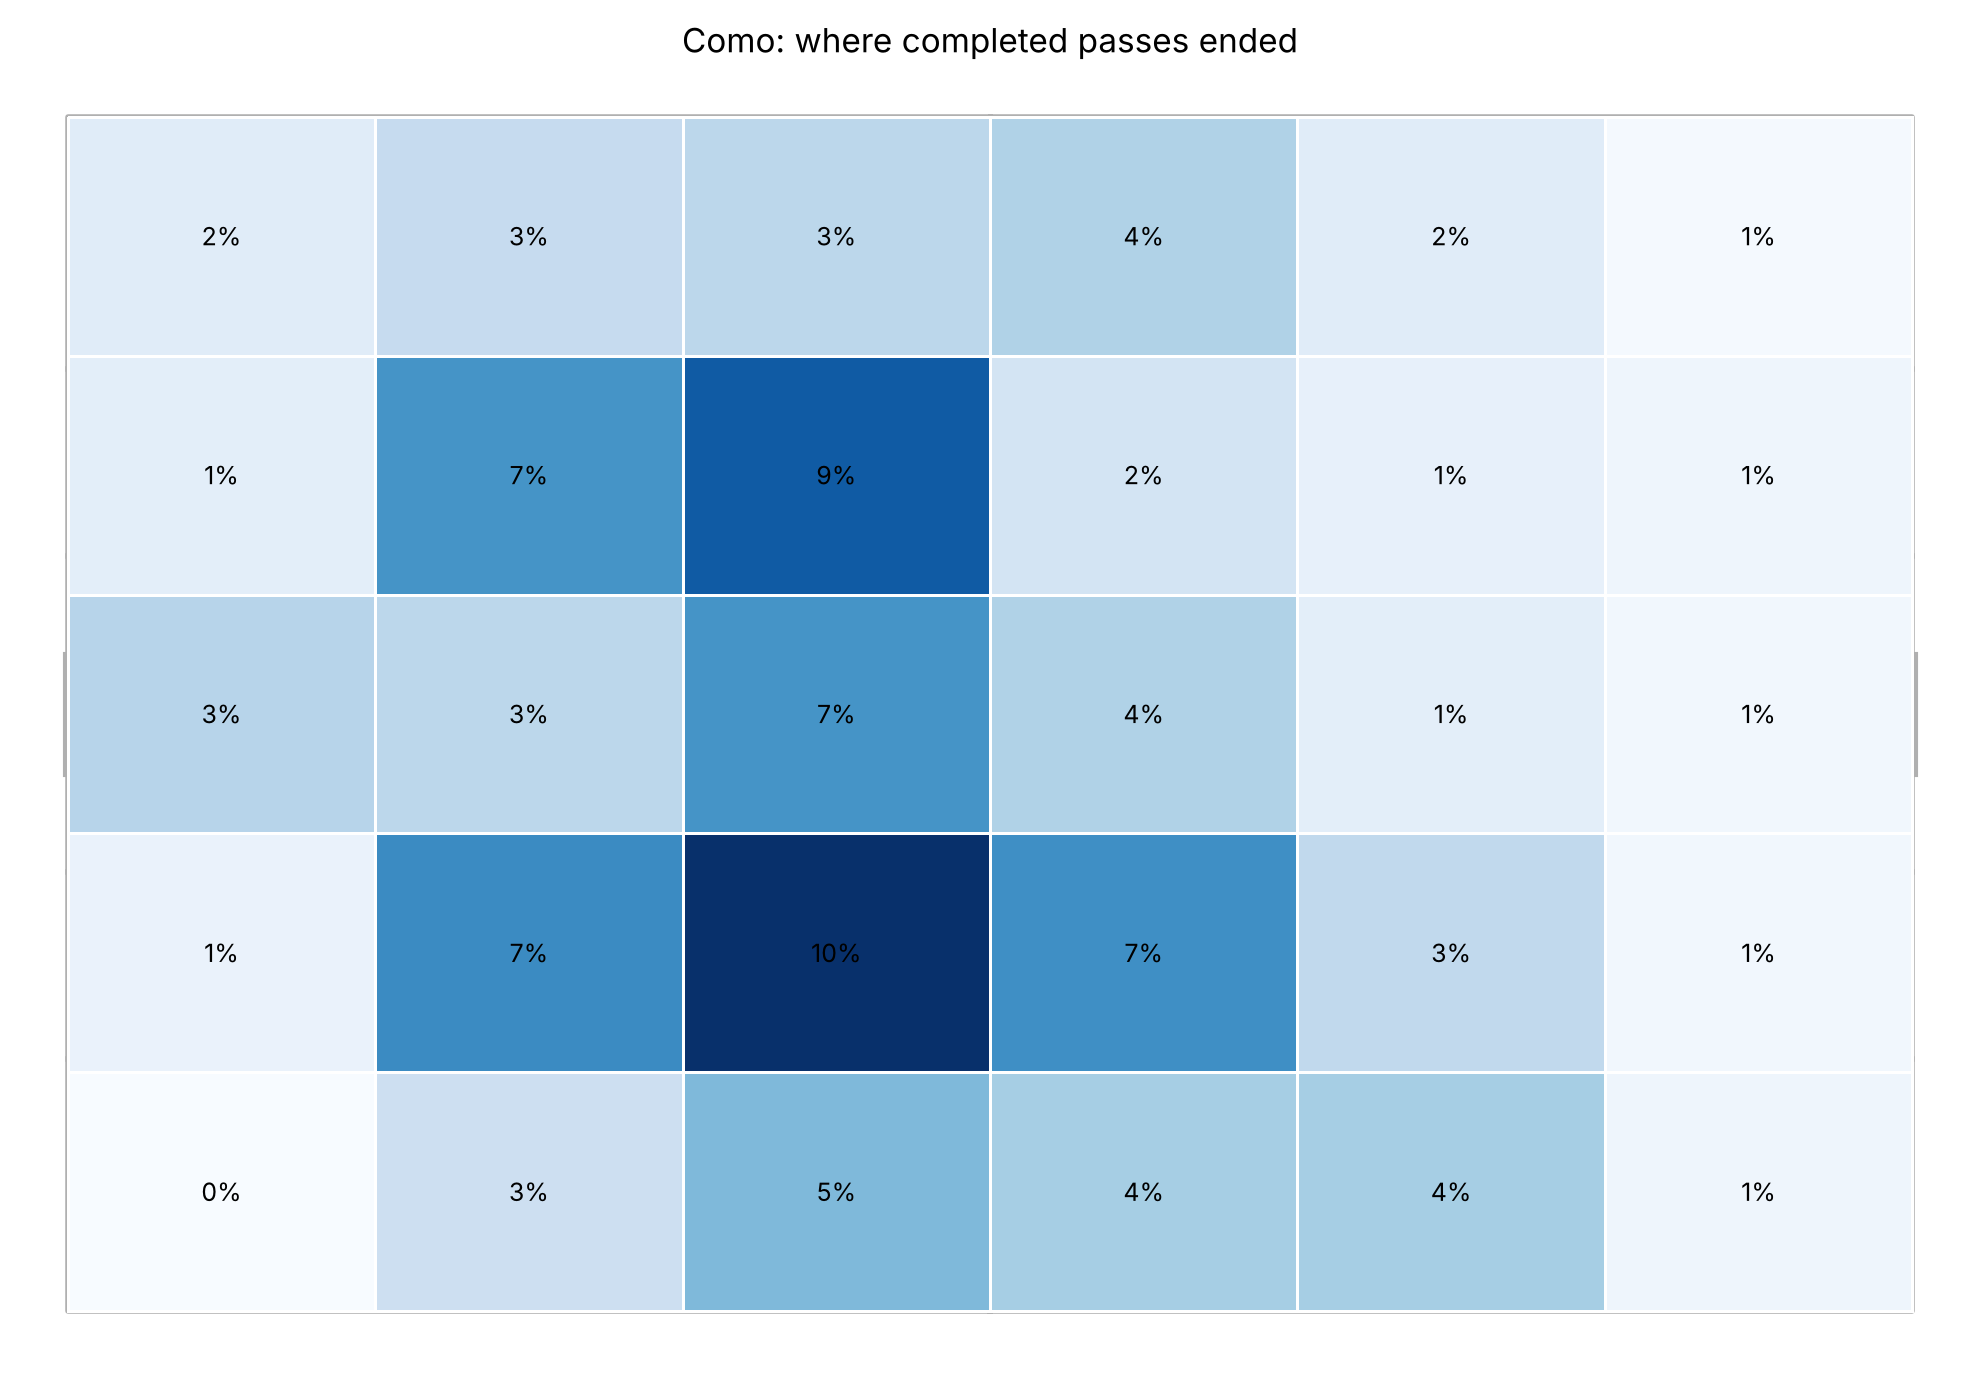

In [20]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(c_stats, ax=ax, cmap="Blues", edgecolors="white")
pitch.label_heatmap(c_stats, ax=ax, str_format="{:.0%}", ha="center", va="center", fontsize=9)

ax.set_title("Como: where completed passes ended")
plt.show()

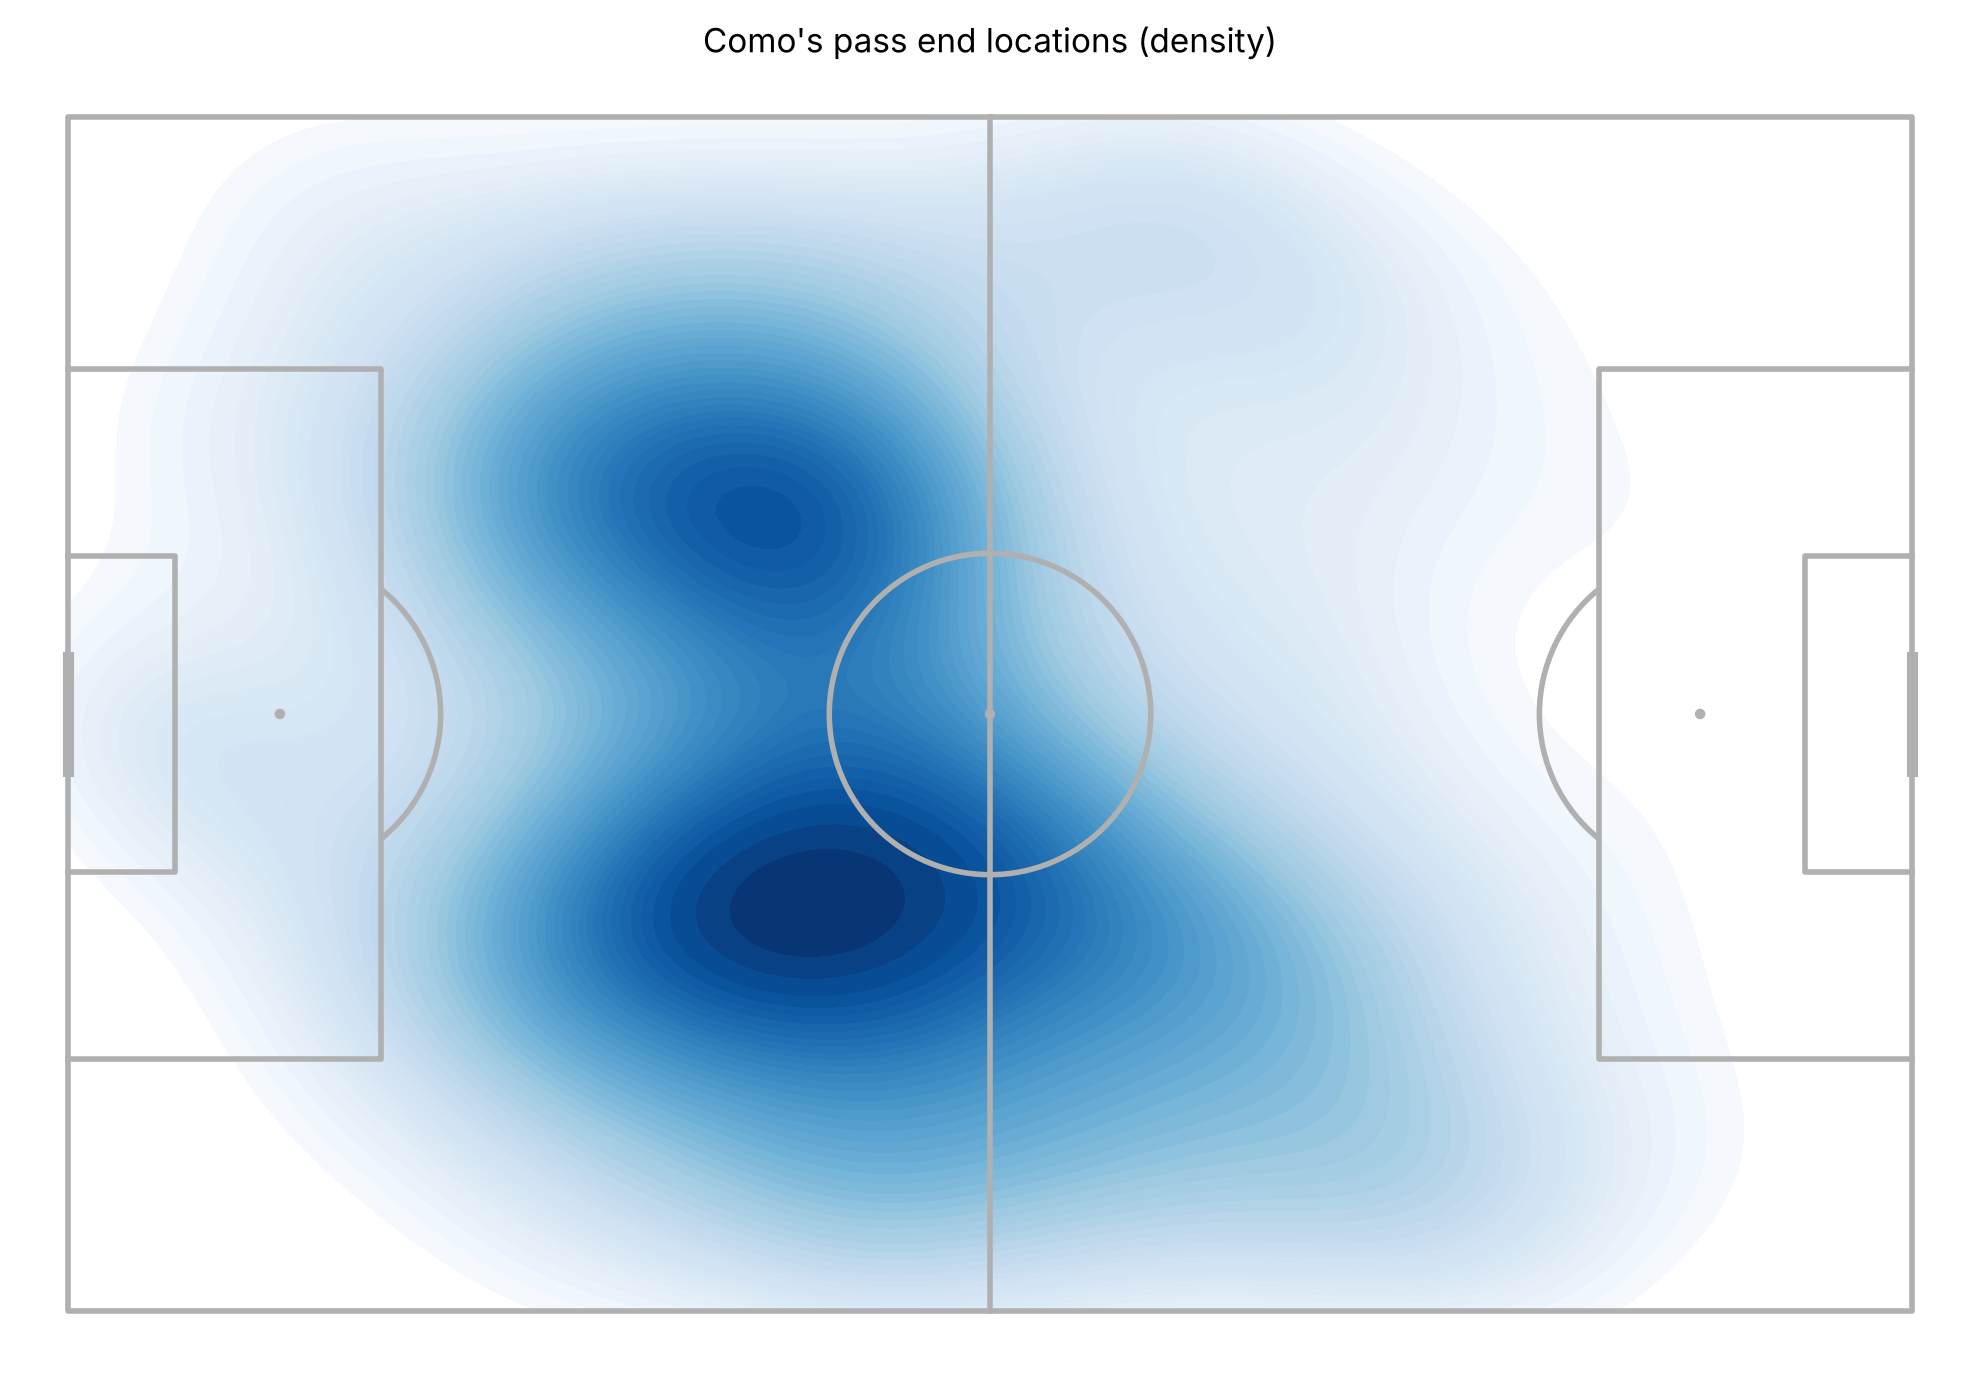

In [21]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.kdeplot(c_completed["end_x"], c_completed["end_y"], ax=ax,
              fill=True, levels=50, cmap="Blues", thresh=0.05)

ax.set_title("Como's pass end locations (density)")
plt.show()

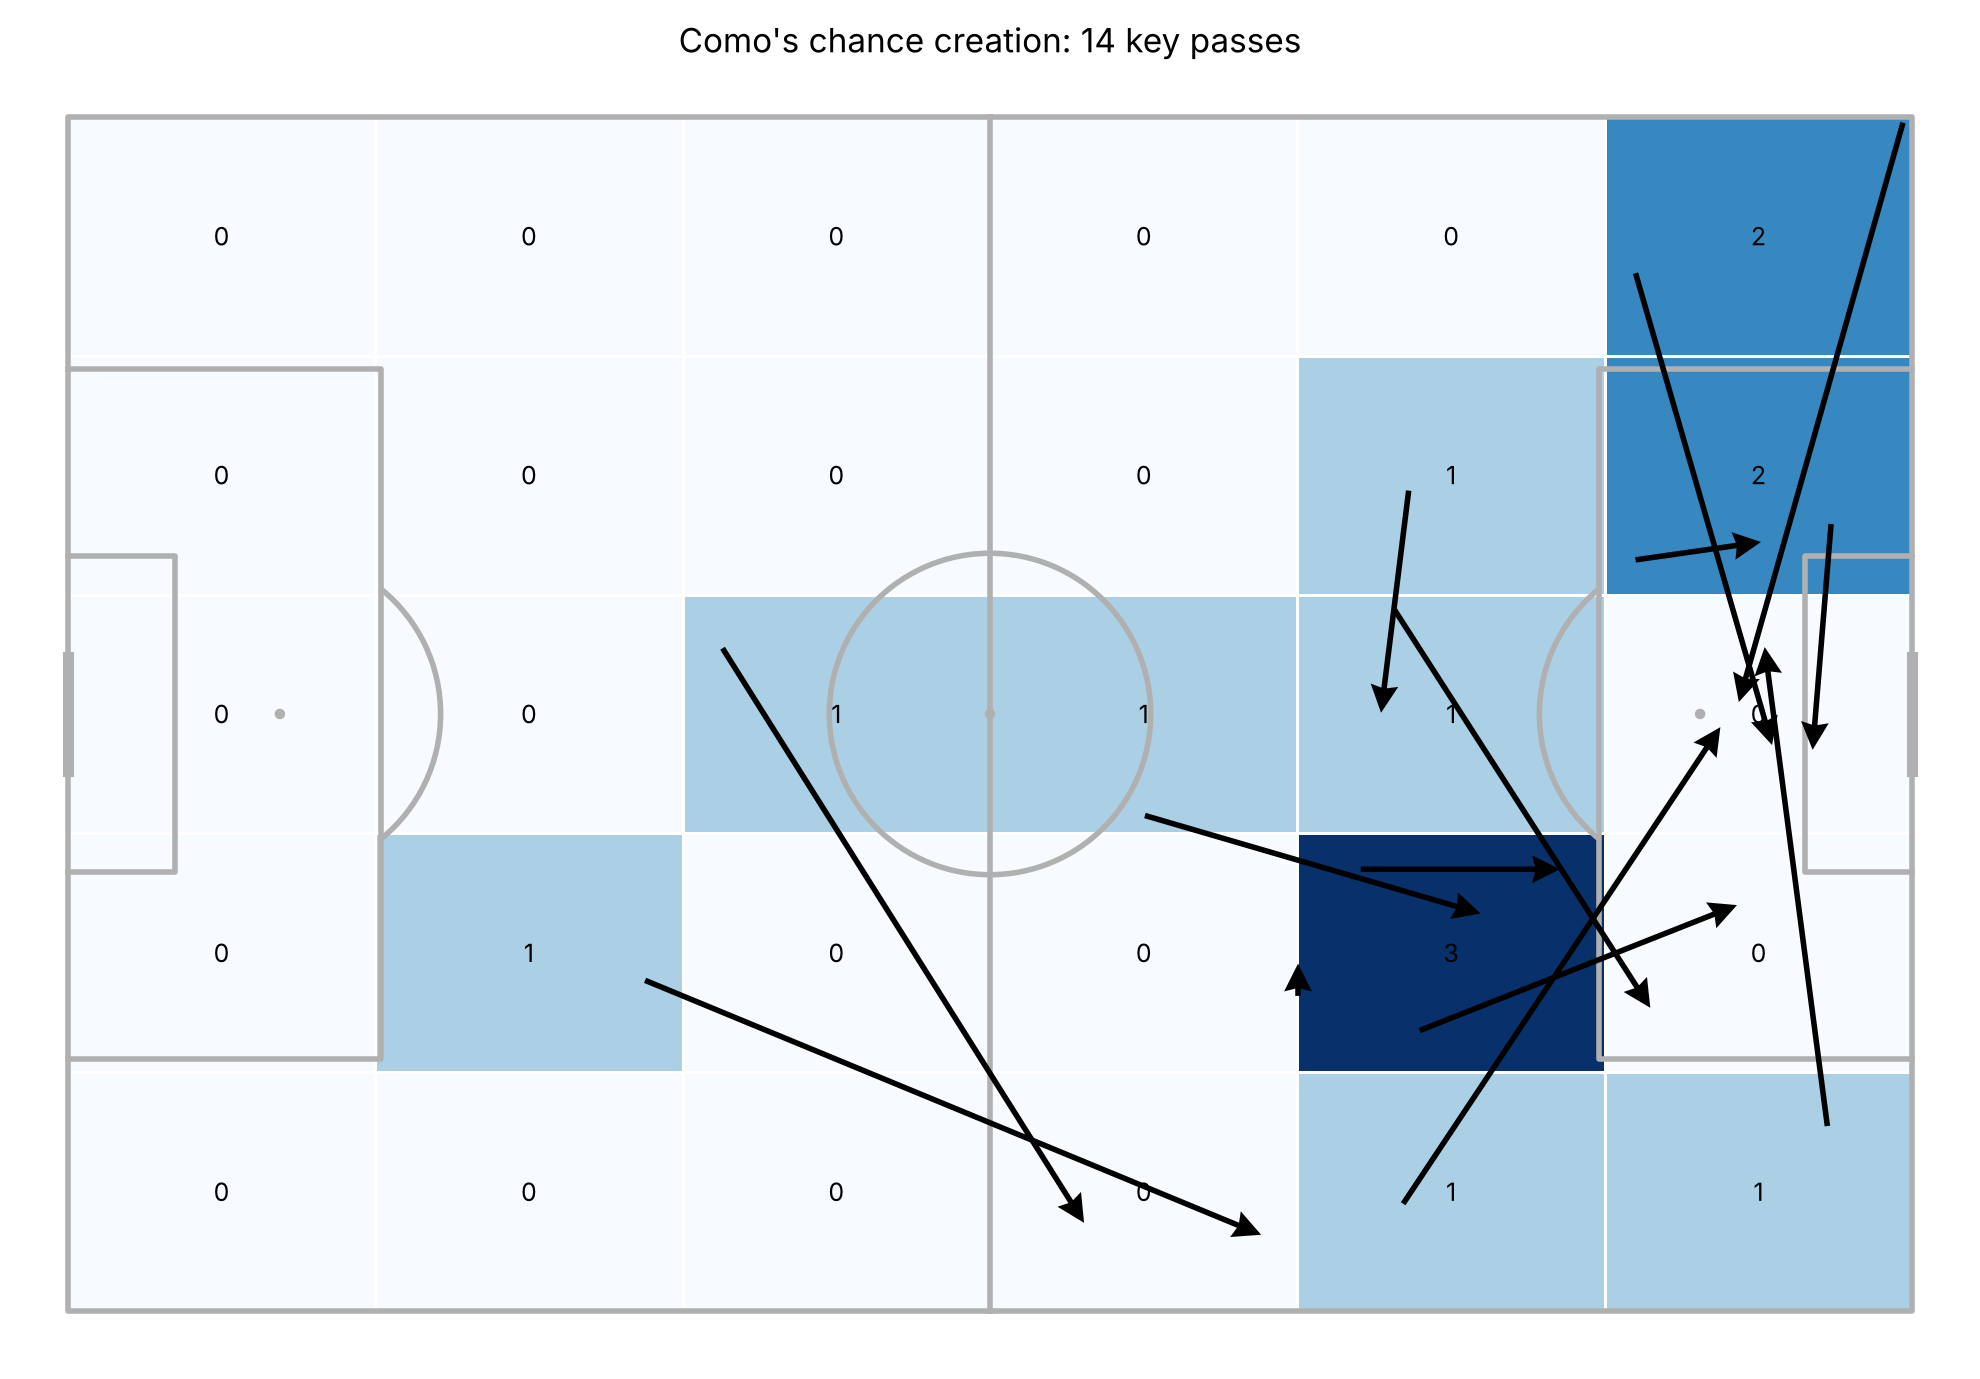

In [22]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(kp_stats, ax=ax, cmap="Blues", edgecolor="white")
pitch.label_heatmap(kp_stats, ax=ax, str_format="{:.0f}",
                    ha="center", va="center", fontsize=9)

pitch.arrows(key_passes["x"], key_passes["y"],
             key_passes["end_x"], key_passes["end_y"],
             ax=ax, width=2, headwidth=5, color="black", zorder=3)

ax.set_title(f"Como's chance creation: {len(key_passes)} key passes")
plt.show()

## 6. Progressive passing

A pass is progressive if it ends at least 25% closer to goal than it started (distances in metres, corners and throw-ins excluded).

In [23]:
events["dist_start"] = np.sqrt(((100 - events["x"]) * 1.05)**2 + ((50 - events["y"]) * 0.68)**2)
events["dist_end"]   = np.sqrt(((100 - events["end_x"]) * 1.05)**2 + ((50 - events["end_y"]) * 0.68)**2)
events["is_progressive"] = events["dist_end"] <= 0.75 * events["dist_start"]
set_piece = events["qualifiers"].str.contains("CornerTaken|ThrowIn", na=False)

c_prog = events[
    (events["team"] == "Como")
    & (events["type"] == "Pass")
    & (events["outcome_type"] == "Successful")
    & (events["is_progressive"])
    & (~set_piece)
]
len(c_prog)

lanes = c_prog["end_y"]

prog_right = (lanes < 33.3).sum()
prog_middle = ((lanes >= 33.3) & (lanes <= 66.7)).sum()
prog_left = (lanes > 66.7).sum()

prog_pass = [len(c_passes), len(c_completed), len(c_prog)]
prog_pass

[681, 611, 37]

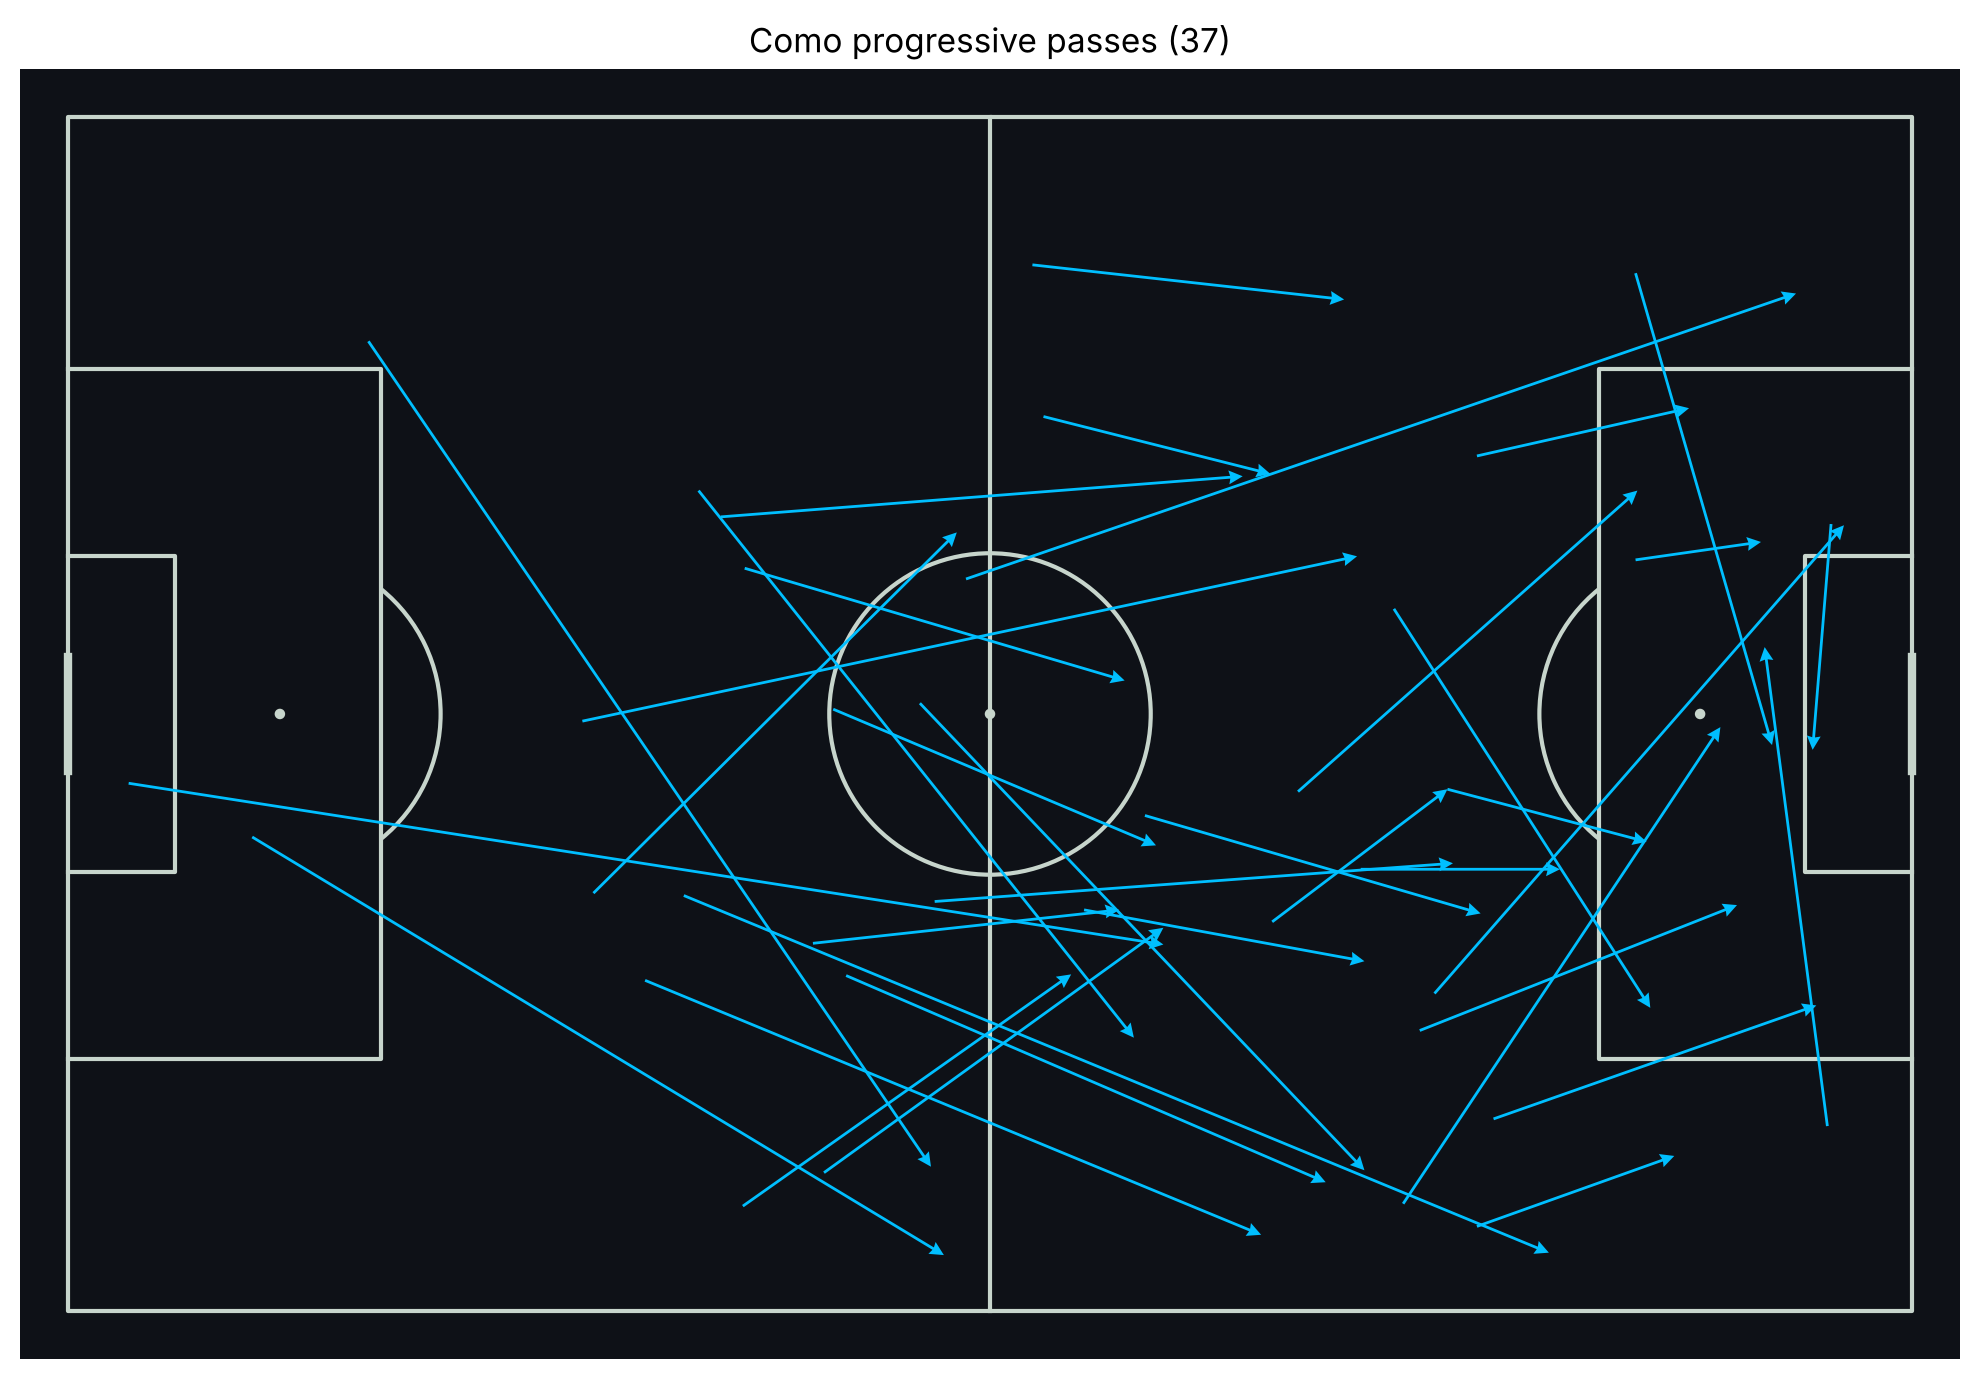

In [24]:
BG = "#0e1117"
LINES = "#c7d5cc"

pitch = Pitch(pitch_type="opta", pitch_color=BG, line_color=LINES, linewidth=1.5, goal_type="line")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.arrows(c_prog["x"], c_prog["y"], c_prog["end_x"], c_prog["end_y"], ax=ax, width=1, headwidth=5, color="deepskyblue")

ax.set_title(f"Como progressive passes ({len(c_prog)})", color="black")
plt.show()

## 7. Zone 14 and the half-spaces

In [25]:
in_z14 = c_completed["end_x"].between(66.7, 83) & c_completed["end_y"].between(33.3, 66.7)
c_z14 = c_completed[in_z14]
len(c_z14)

in_hs = c_completed["end_x"].between(66.7, 100) & (
    c_completed["end_y"].between(21.1, 36.8) | c_completed["end_y"].between(63.2, 78.9)
)
c_hs = c_completed[in_hs]
len(c_hs)

c_set_piece = c_completed["qualifiers"].str.contains("CornerTaken|ThrowIn")

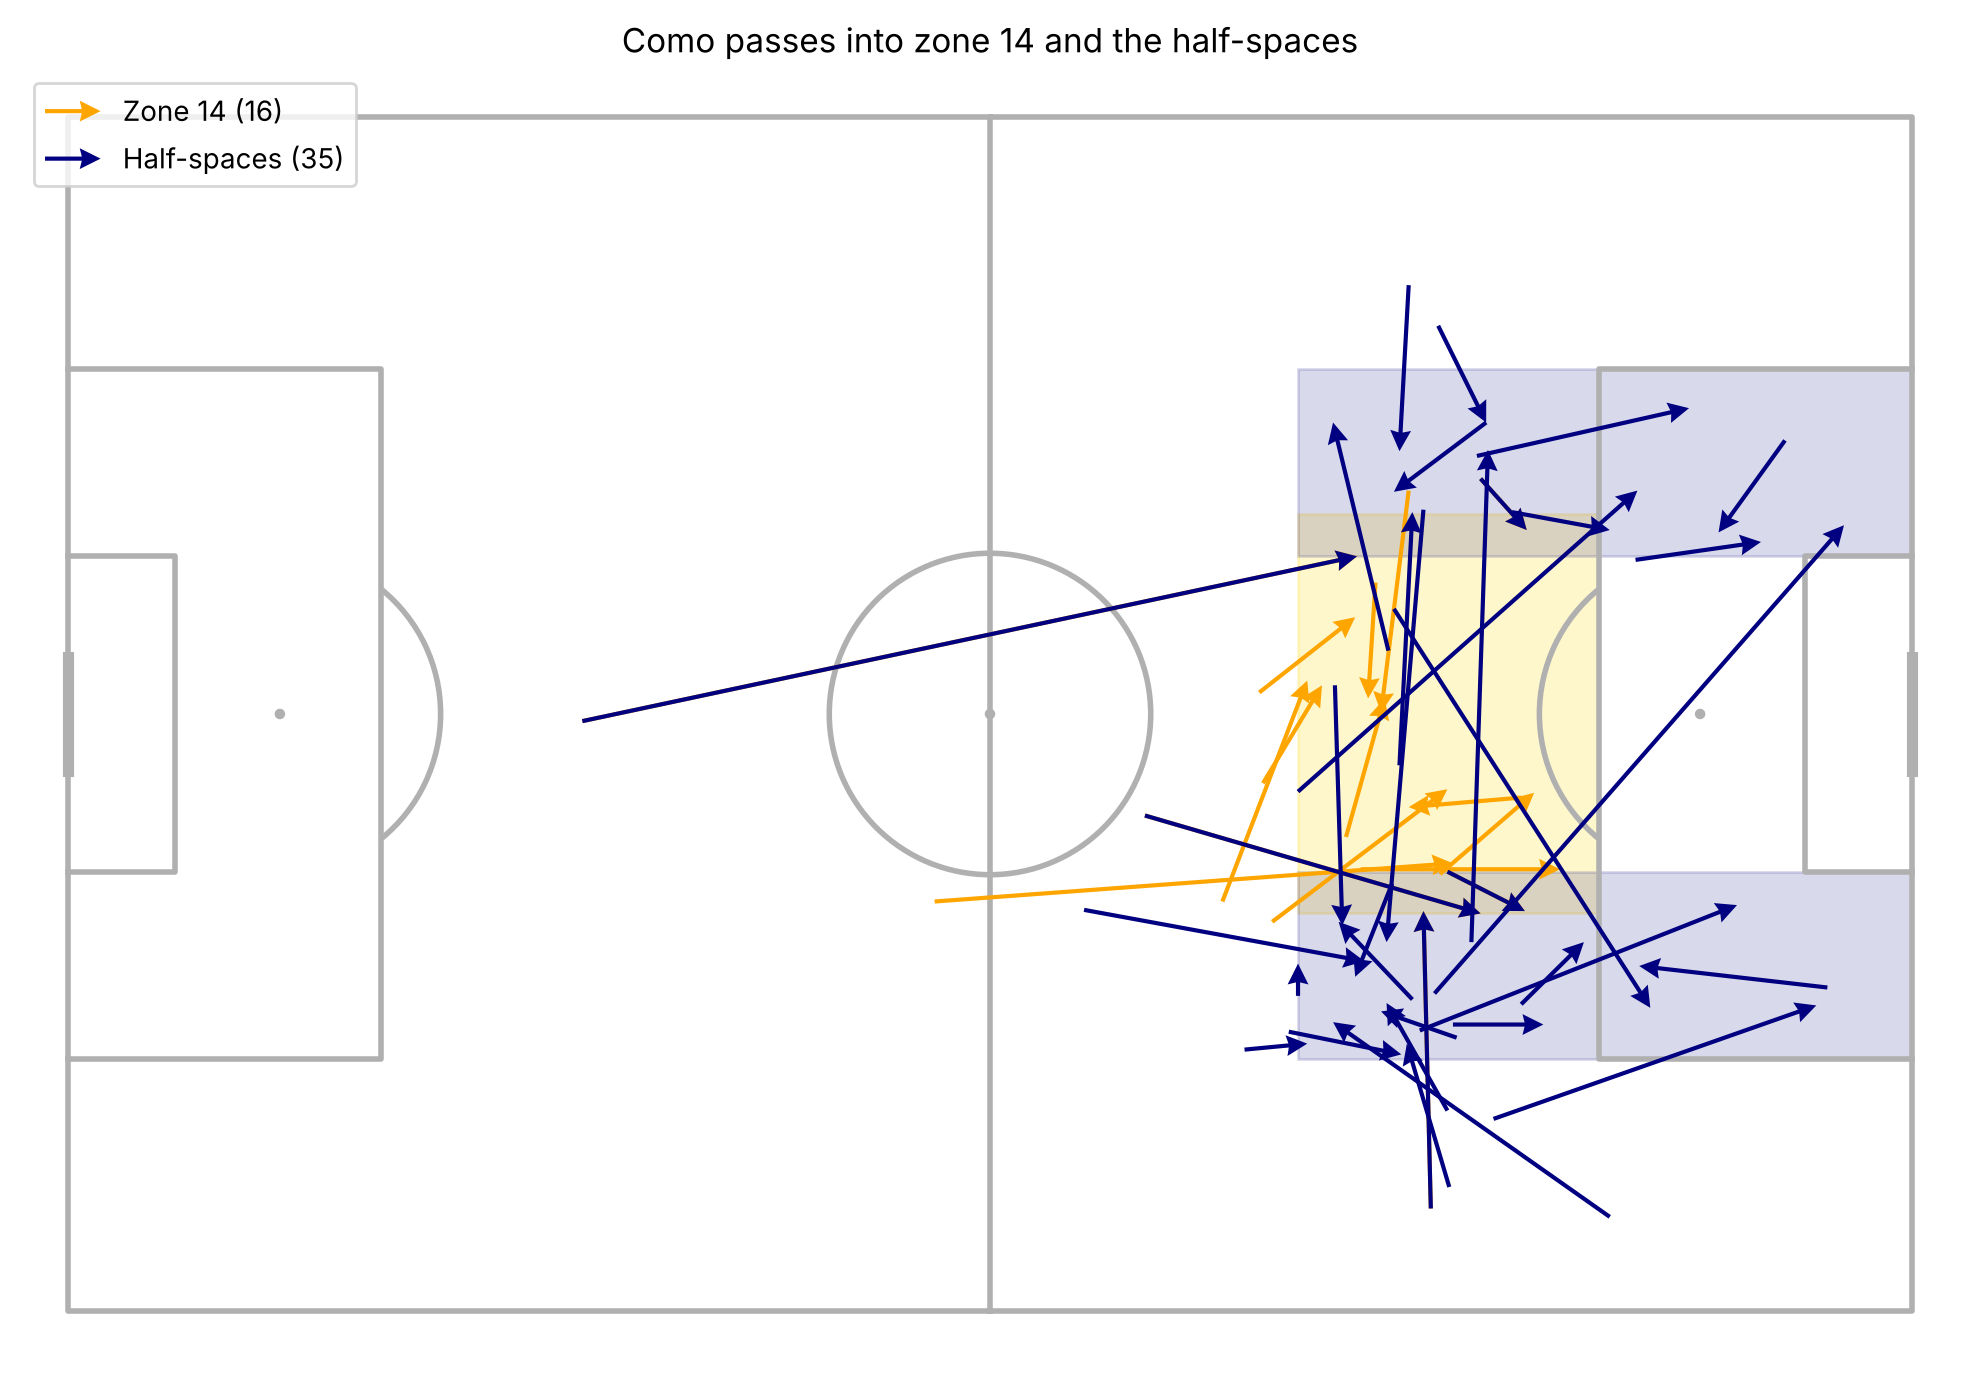

In [26]:
from matplotlib.patches import Rectangle

pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

# shade the zones: Rectangle((bottom-left x, bottom-left y), width, height)
ax.add_patch(Rectangle((66.7, 33.3), 83 - 66.7, 66.7 - 33.3, color="gold", alpha=0.2, zorder=1))
ax.add_patch(Rectangle((66.7, 21.1), 100 - 66.7, 36.8 - 21.1, color="navy", alpha=0.15, zorder=1))
ax.add_patch(Rectangle((66.7, 63.2), 100 - 66.7, 78.9 - 63.2, color="navy", alpha=0.15, zorder=1))

# arrows on top
pitch.arrows(c_z14["x"], c_z14["y"], c_z14["end_x"], c_z14["end_y"],
             ax=ax, width=1.5, headwidth=5, color="orange", zorder=3, label=f"Zone 14 ({len(c_z14)})")
pitch.arrows(c_hs["x"], c_hs["y"], c_hs["end_x"], c_hs["end_y"],
             ax=ax, width=1.5, headwidth=5, color="navy", zorder=3, label=f"Half-spaces ({len(c_hs)})")

ax.legend(loc="upper left")
ax.set_title("Como passes into zone 14 and the half-spaces")
plt.show()

## 8. High turnovers

Ball recoveries, interceptions and won tackles within 40 m of the opponent's goal.

In [27]:
wins = events["type"].isin(["BallRecovery", "Interception"])
won_tackle = (events["type"] == "Tackle") & (events["outcome_type"] == "Successful")
near_goal = events["dist_start"] <= 40

[wins.sum(), won_tackle.sum(), near_goal.sum()]

[np.int64(110), np.int64(24), np.int64(322)]

In [28]:
c_ht = events[(events["team"] == "Como") & (wins | won_tackle) & near_goal]
len(c_ht)

l_ht = events[(events["team"] == "Lens") & (wins | won_tackle) & near_goal]

[len(c_ht), len(l_ht)]

[8, 13]

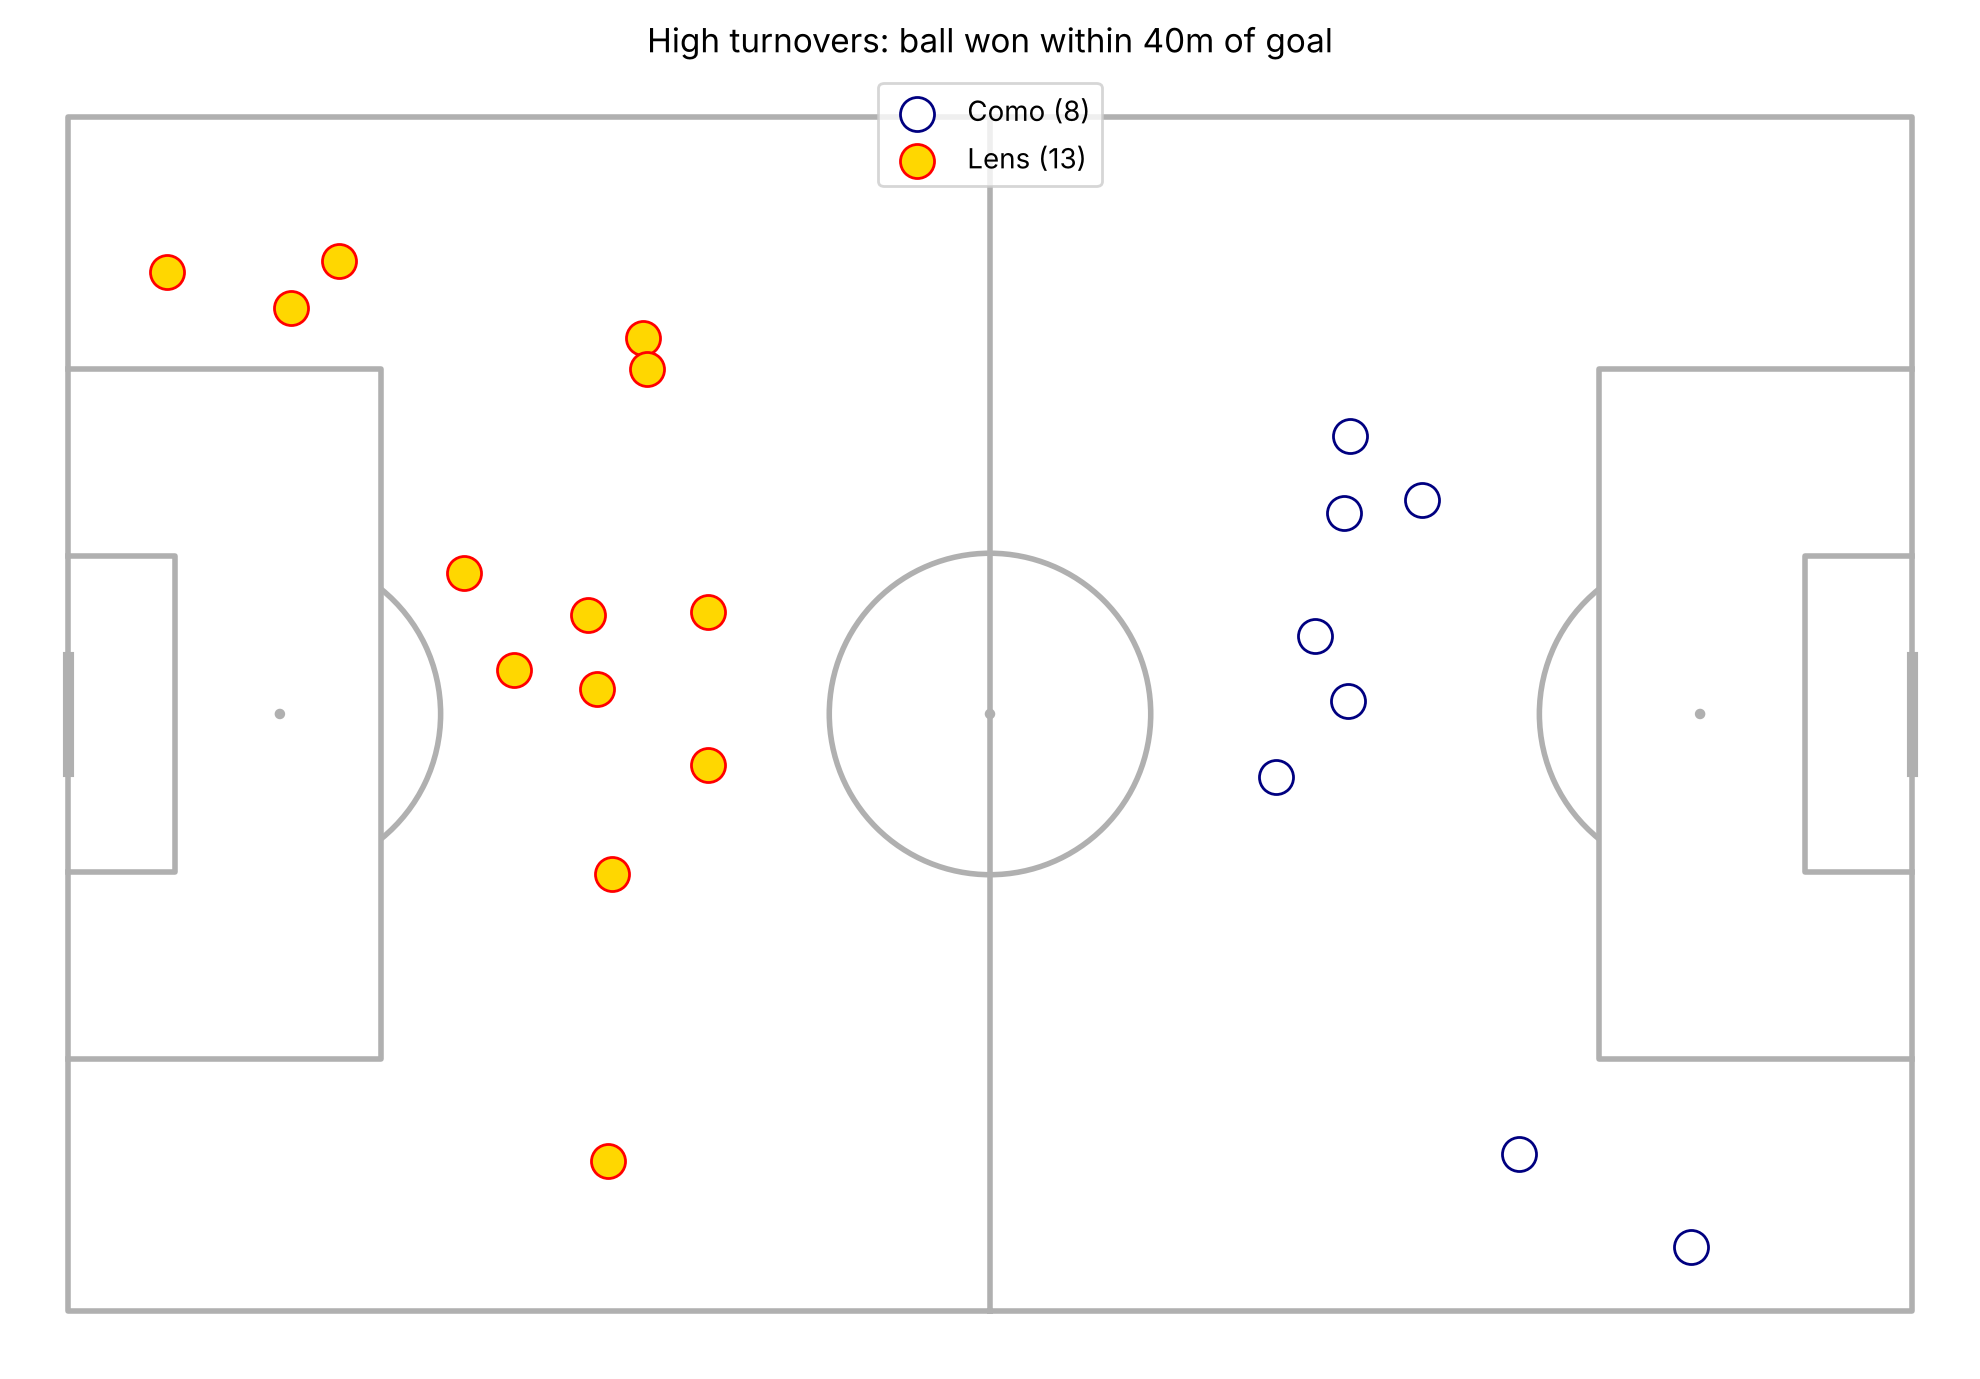

In [29]:
l_ht_flipped = l_ht.copy()
l_ht_flipped["x"] = 100 - l_ht_flipped["x"]
l_ht_flipped["y"] = 100 - l_ht_flipped["y"]                     # the same idea, for y

pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.scatter(c_ht["x"], c_ht["y"], ax=ax, s=150, color="white",
              edgecolors="navy", zorder=3, label=f"Como ({len(c_ht)})")
pitch.scatter(l_ht_flipped["x"], l_ht_flipped["y"], ax=ax, s=150, color="gold",
              edgecolors="red", zorder=3, label=f"Lens ({len(l_ht)})")

ax.legend(loc="upper center")
ax.set_title("High turnovers: ball won within 40m of goal")
plt.show()

## 9. Expected threat (xT) and match momentum

Each completed pass scores the xT of where it ended minus where it started (negative values set to 0).

In [30]:
xt_grid = pd.read_csv(
    "https://raw.githubusercontent.com/mckayjohns/youtube-videos/main/data/xT_Grid.csv",
    header=None
).values
xt_grid.shape

(8, 12)

In [31]:
passes_ok = events[(events["type"] == "Pass") & (events["outcome_type"] == "Successful")].copy()

passes_ok["start_col"] = np.clip((passes_ok["x"] / 100 * 12).astype(int), 0, 11)
passes_ok["start_row"] = np.clip((passes_ok["y"] / 100 * 8).astype(int), 0, 7)
passes_ok["end_col"]   = np.clip((passes_ok["end_x"] / 100 * 12).astype(int), 0, 11)
passes_ok["end_row"]   = np.clip((passes_ok["end_y"] / 100 * 8).astype(int), 0, 7)

start_xt = xt_grid[passes_ok["start_row"], passes_ok["start_col"]]
end_xt = xt_grid[passes_ok["end_row"], passes_ok["end_col"]]

passes_ok["xt"] = np.clip(end_xt - start_xt, 0, None)

In [32]:
(passes_ok[passes_ok["team"] == "Como"]
    .groupby("player")["xt"].sum()
    .sort_values(ascending=False)
    .head(5))

player
Luis Milla        0.647639
Álex Valle        0.268911
Nico Paz          0.148713
Tasos Douvikas    0.124774
Jacobo Ramón      0.108364
Name: xt, dtype: float64

In [33]:
c_min = passes_ok[passes_ok["team"] == "Como"].groupby("minute")["xt"].sum()
l_min = passes_ok[passes_ok["team"] == "Lens"].groupby("minute")["xt"].sum()

c_goal_mins = C_Goals["minute"]
l_goal_mins = L_Goals["minute"]
list(c_goal_mins), list(l_goal_mins)

([6, 31, 39, 46, 52, 56, 61, 68, 90], [64])

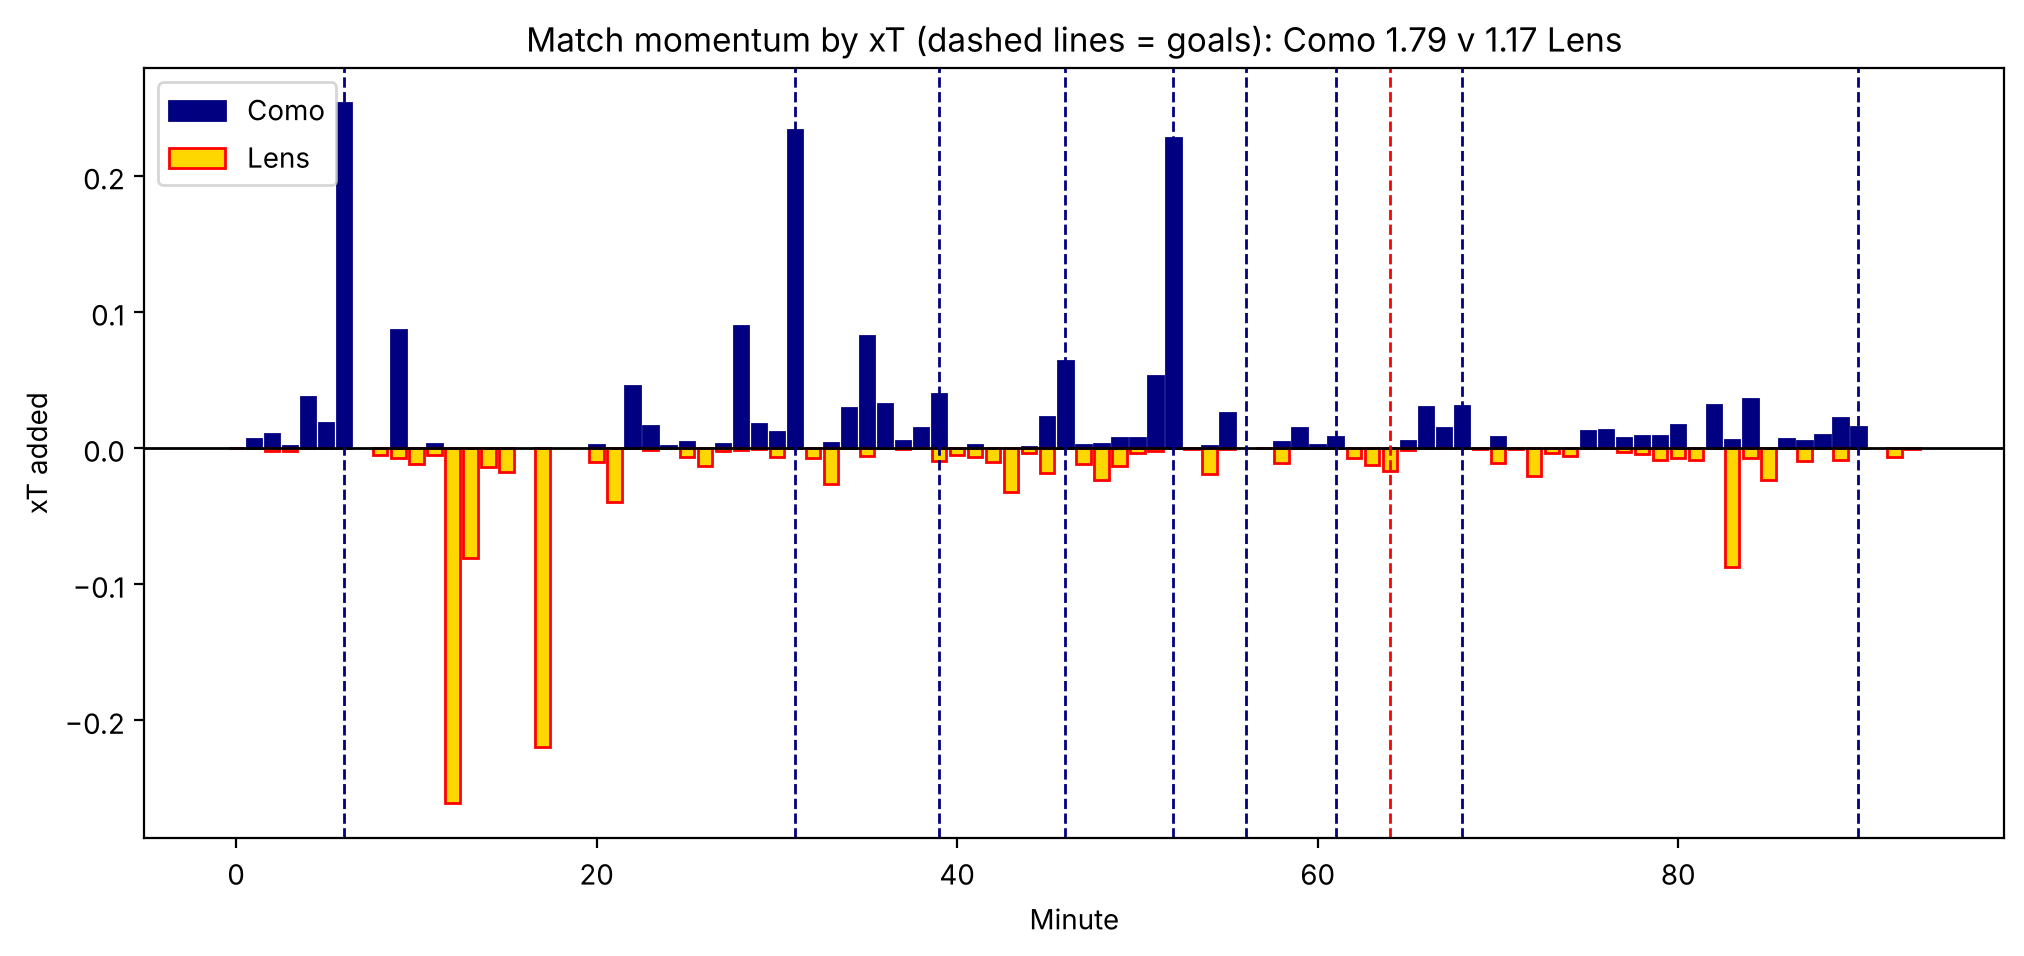

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(c_min.index, c_min.values, color="navy", edgecolor="navy", label="Como")
ax.bar(l_min.index, -l_min.values, color="gold", edgecolor="red", label="Lens")     # downwards: make it negative
ax.axhline(0, color="black", linewidth=1)

for m in c_goal_mins:
    ax.axvline(m, color="navy", linestyle="--", linewidth=1)
for m in l_goal_mins:
    ax.axvline(m, color="red", linestyle="--", linewidth=1)

ax.set_xlabel("Minute")
ax.set_ylabel("xT added")
ax.set_title(f"Match momentum by xT (dashed lines = goals): Como {c_min.sum():.2f} v {l_min.sum():.2f} Lens")
ax.legend()
plt.show()

## 10. Man of the match: Tasos Douvikas

A hat-trick and an assist in 60 minutes. Carries aren't in the data, so they're built from consecutive touches: the same team keeps the ball, the previous action succeeded, and the player moved it 3–60 m.

In [35]:
events.loc[events["player"].str.contains("Douvikas", na=False), "player"].unique()

<StringArray>
['Tasos Douvikas']
Length: 1, dtype: str

In [36]:
Player = "Tasos Douvikas"
player_events = events[events["player"] == Player]
len(player_events)
player_events["type"].value_counts()

type
Pass               7
Goal               3
BallTouch          3
TakeOn             2
Clearance          1
Aerial             1
BallRecovery       1
Foul               1
CornerAwarded      1
OffsidePass        1
SubstitutionOff    1
Name: count, dtype: int64

In [37]:
passes = player_events[player_events["type"] == "Pass"]
completed = passes[passes["outcome_type"] == "Successful"] 
incomplete = passes[passes["outcome_type"] == "Unsuccessful"] 

In [38]:
touches = events[events["is_touch"] == True].copy()

touches["prev_team"]    = touches["team"].shift(1)
touches["prev_period"]  = touches["period"].shift(1)
touches["prev_outcome"] = touches["outcome_type"].shift(1)

touches["carry_start_x"] = touches["end_x"].fillna(touches["x"]).shift(1)
touches["carry_start_y"] = touches["end_y"].fillna(touches["y"]).shift(1)       

In [39]:
dx = (touches["x"] - touches["carry_start_x"]) * 1.05
dy = (touches["y"] - touches["carry_start_y"]) * 0.68                          
touches["carry_dist"] = np.sqrt(dx**2 + dy**2)

is_carry = (
    (touches["team"] == touches["prev_team"])
    & (touches["period"] == touches["prev_period"])                 # same period
    & (touches["prev_outcome"] == "Successful")                 # previous was successful
    & (touches["carry_dist"].between(3, 60))
)
carries = touches[is_carry & (touches["player"] == Player)]
len(carries)

9

In [40]:
carries[["minute", "type", "carry_start_x", "carry_start_y", "x", "y", "carry_dist"]]

,minute,type,carry_start_x,carry_start_y,x,y,carry_dist
170,6,Goal,92.0,55.6,97.1,48.2,7.348268
333,21,Pass,33.3,35.3,35.4,14.3,14.449236
557,33,TakeOn,48.8,33.3,55.4,25.4,8.768311
579,35,Pass,87.9,75.6,91.6,73.0,4.268378
668,39,Pass,63.7,69.9,71.9,58.8,11.450083
1032,55,TakeOn,59.0,39.0,65.3,42.2,6.963706
1033,55,OffsidePass,65.3,42.2,70.4,31.1,9.254638
1049,56,Goal,76.6,33.3,85.9,36.8,10.050852
1100,59,Pass,70.3,29.3,70.5,24.2,3.474352


In [41]:
player_touches = player_events[player_events["is_touch"] == True]
len(player_touches)

18

In [42]:
D_Shots = events[(events["is_shot"] == True) & (events["player"] == Player)]
D_Goals = D_Shots[D_Shots["is_goal"] == True]
len(D_Goals)

3

In [43]:
D_assists = passes[passes["qualifiers"].str.contains("IntentionalGoalAssist", na=False)]
minutes_played = player_events[player_events["type"] == "SubstitutionOff"]["minute"].min()

{"goals": len(D_Goals), "shots": len(D_Shots), "assists": len(D_assists),
 "touches": len(player_touches), "carries": len(carries),
 "passes completed": len(completed), "passes incomplete": len(incomplete),
 "minutes": minutes_played}

{'goals': 3,
 'shots': 3,
 'assists': 1,
 'touches': 18,
 'carries': 9,
 'passes completed': 5,
 'passes incomplete': 2,
 'minutes': np.int64(60)}

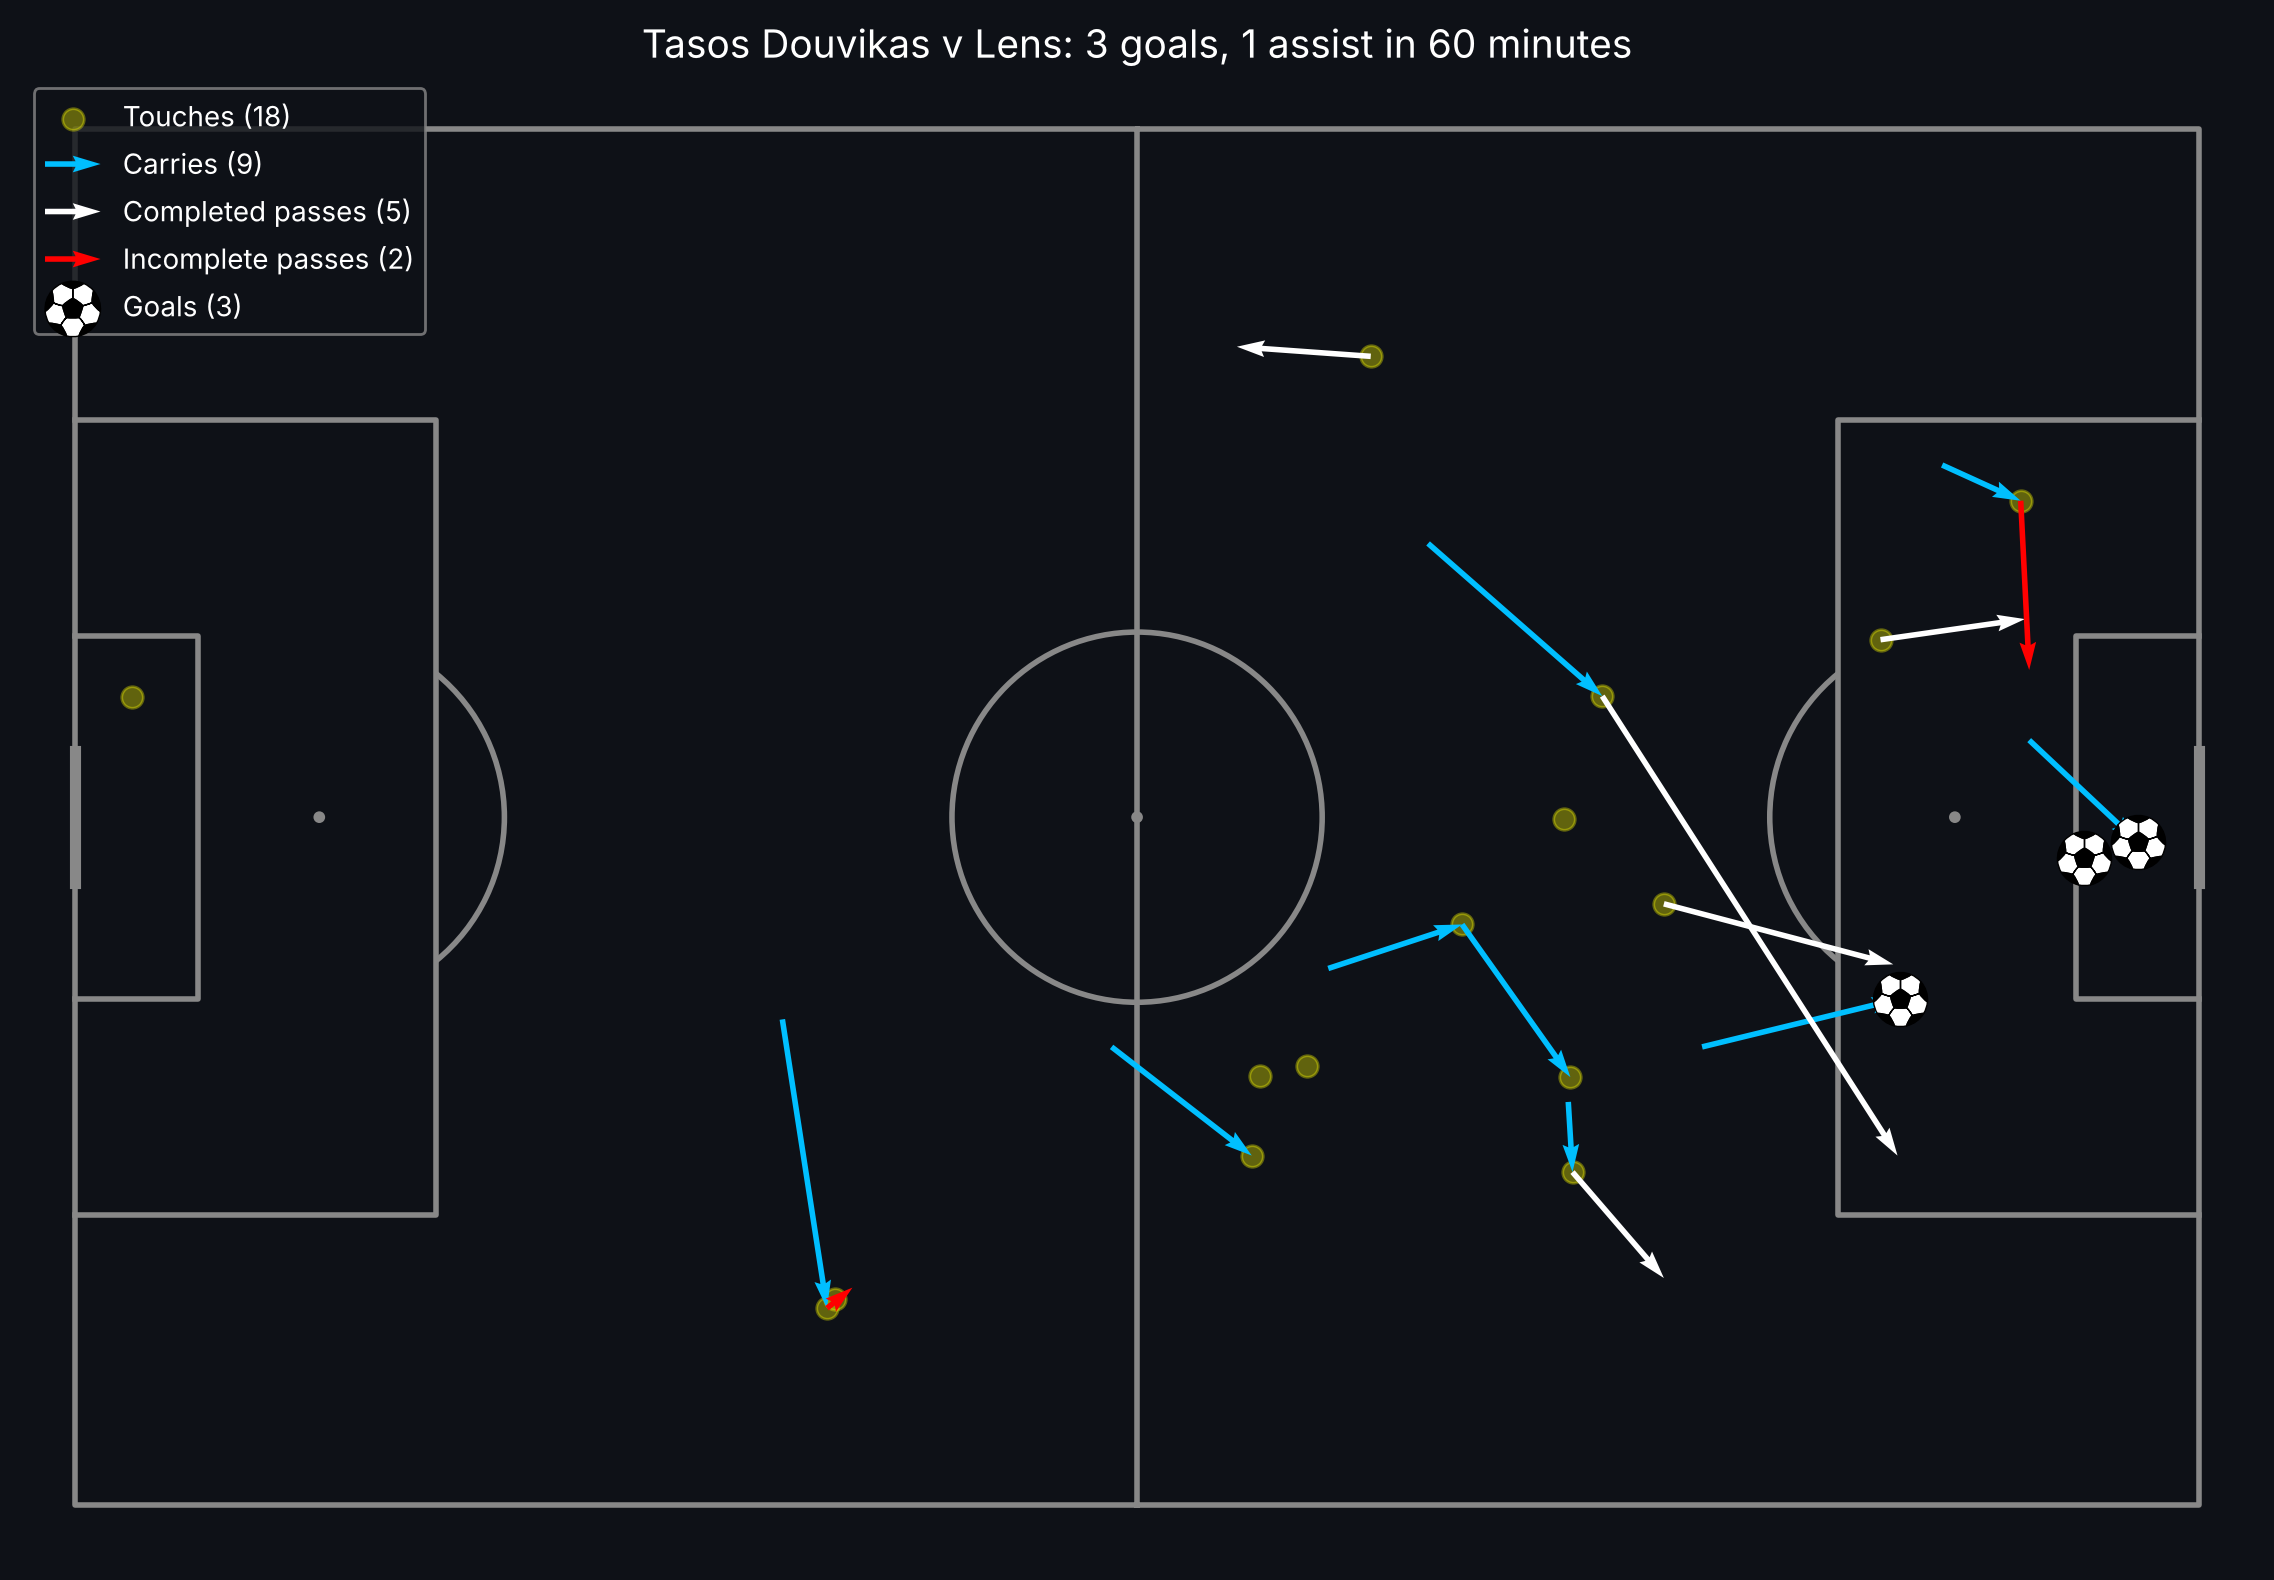

In [44]:
pitch = Pitch(pitch_type="opta", pitch_color="#0e1117", line_color="#888888")
fig, ax = pitch.draw(figsize=(12, 8))

pitch.scatter(player_touches["x"], player_touches["y"], ax=ax, s=60, color="yellow", alpha=0.35, zorder=1, label=f"Touches ({len(player_touches)})")
pitch.arrows(carries["carry_start_x"], carries["carry_start_y"], carries["x"], carries["y"], ax=ax, color="deepskyblue", width=2, zorder=2, label=f"Carries ({len(carries)})")
pitch.arrows(completed["x"], completed["y"], completed["end_x"], completed["end_y"], ax=ax, color="white", width=2, zorder=3, label=f"Completed passes ({len(completed)})")
pitch.arrows(incomplete["x"], incomplete["y"], incomplete["end_x"], incomplete["end_y"], ax=ax, color="red", width=2, zorder=3, label=f"Incomplete passes ({len(incomplete)})")
pitch.scatter(D_Goals["x"], D_Goals["y"], ax=ax, s=400, marker="football", zorder=4, label=f"Goals ({len(D_Goals)})")

ax.legend(loc="upper left", facecolor="#0e1117", labelcolor="white", edgecolor="#888888")
ax.set_title(f"Tasos Douvikas v Lens: {len(D_Goals)} goals, 1 assist in {minutes_played} minutes", color="white", fontsize=14)
fig.set_facecolor("#0e1117")
plt.show()